# PyTorch Fundamentals: From Tensors to a Trained Neural Network
### Notebook 1 of 2 · First course on artificial neural networks

You already know what an MLP computes, how gradient descent works and what backpropagation does. This notebook teaches you to **write all of it in PyTorch**.

By the end you will be able to:
- create and reshape tensors without shape bugs;
- explain what `loss.backward()` computes and why `optimizer.zero_grad()` exists;
- build models with `nn.Module`, choose the right loss, and feed data with `Dataset` and `DataLoader`;
- train and honestly evaluate an MLP on **Fashion-MNIST** (≈ 88–89 % test accuracy).

**Notebook 2** covers training craft: initialization, optimizers and schedules, regularization, evaluation, a first look at convolution, and debugging.

## Instructor-guided plan — Session 1 (180 minutes)

**Audience:** students already know MLPs, backpropagation, classical ML, basic calculus and Python, but are new to PyTorch. **Instructor** runs demonstrations on an RTX 2080 Ti; students may repeat them on Colab later.

| Minutes | Live focus | Sections / demonstration |
| --- | --- | --- |
| 0–15 | See the complete training pipeline | Chapter 0 |
| 15–50 | Tensor shapes, broadcasting, matrix multiplication, devices | Chapter 1 (selected cells) |
| 50–80 | Autograd, gradient accumulation, `no_grad` | Chapter 2 (selected cells) |
| 80–90 | Break | — |
| 90–120 | Linear regression: manual → autograd → optimizer → module | Chapter 3 |
| 120–145 | Modules and classification losses | Chapters 4–5 (selected cells) |
| 145–170 | Fashion-MNIST: a working MLP, validation, evaluation | Chapters 6–7 (selected cells; predownload data) |
| 170–180 | Debugging: shapes, initial loss, one-batch overfit | Chapter 7.9; recap |

**The rest is optional self-study.** In particular, exercises, detailed custom datasets, advanced tensor operations and extended experiment runs are *not* additional classroom requirements. Instructor should execute lengthy download/training cells in advance or use the notebook's fast-run settings; durations are teaching allocations, not measured GPU runtimes.

**Learning target:** build an MLP, move data to a device, train it with a correct loss/optimizer loop, use a separate validation set, and diagnose basic bugs.

**Conventions.** 🤔 **Predict** = decide what a cell prints *before* running it. ⚠️ = a common bug, often silent. 🧪 = optional exercise (★ easy … ★★★ hard), sometimes with a 🔎 self-check. ✅ cells show solutions and run only if `RUN_SOLUTIONS = True`.

**Reproducibility and versions:** run cells in order from a clean kernel. For Colab use *Runtime → Restart session and run all*. The notebook runs on whatever recent PyTorch (2.6 or newer) the machine has; the setup cell prints the Python, `torch` and `torchvision` versions and the device. Numerical results depend on package versions, hardware, and random variation, so the numbers quoted in the text are typical values, not targets.

---
# Chapter 0. Setup and the big picture

**Colab:** *Runtime → Change runtime type → T4 GPU*, then run the cell below. It should print `device: cuda`.
**Own machine:** install `torch`, `torchvision` and `matplotlib` from [pytorch.org](https://pytorch.org/get-started/locally/). Without a GPU everything still works, only Chapter 7 is slower.

In [ ]:
# ---- Setup: run this cell first ------------------------------------------------
import math, platform, random, time
from pathlib import Path

import numpy as np
import torch
import torch.nn as nn                  # layers, models, losses  (convention: "nn")
import torch.nn.functional as F        # the same operations as plain functions (convention: "F")
import torchvision                     # datasets and image tools
import matplotlib.pyplot as plt

_ver = tuple(int(p) for p in torch.__version__.split("+")[0].split(".")[:2])
if _ver < (2, 6):
    print("⚠️  This notebook assumes PyTorch >= 2.6 (you have", torch.__version__, "). Please upgrade.")

FAST_DEV_RUN = False   # True = tiny data and 1 epoch everywhere: a quick smoke test of the whole notebook
RUN_SOLUTIONS = False  # True = also execute the hidden exercise solutions during "Run all" (slower)
DATA_DIR = Path("./data")
DATA_DIR.mkdir(exist_ok=True)

# Use the best available hardware: an NVIDIA GPU ("cuda"), an Apple-silicon GPU ("mps"), or the CPU.
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

def sync(dev=None) -> None:
    # GPU work is asynchronous: wait until it has finished (needed before reading a clock).
    dev = dev or device
    if dev.type == "cuda":
        torch.cuda.synchronize()
    elif dev.type == "mps":
        torch.mps.synchronize()

def set_seed(seed: int = 0) -> None:
    # Make random numbers repeatable: Python, NumPy and PyTorch each have their own generator.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)            # also seeds every GPU

def n_epochs(full: int) -> int:
    # Number of training epochs: `full` normally, 1 in smoke-test mode.
    return 1 if FAST_DEV_RUN else full

def maybe_subset(ds, n: int = 512):
    # The whole dataset normally; only its first n items in smoke-test mode.
    return torch.utils.data.Subset(ds, range(min(n, len(ds)))) if FAST_DEV_RUN else ds

RESULTS = {}           # the numbers YOU measure, collected as you go and summarized at the end
def record(name, value):
    RESULTS[name] = value
    print(f"📝 recorded  {name}: {value:.4f}")

def self_check(name, test):
    # Test the function YOU defined under `name` and report pass/fail without revealing the solution.
    fn = globals().get(name)
    if fn is None:
        print(f"ℹ️  Define `{name}` in the cell above first, then run this cell again.")
        return
    try:
        test(fn)
        print(f"✅ `{name}` passed all checks.")
    except AssertionError as e:
        print(f"❌ `{name}` failed a check: {e}")
    except Exception as e:
        print(f"❌ `{name}` raised {type(e).__name__}: {e}")

print(f"Python {platform.python_version()} | torch {torch.__version__} | torchvision {torchvision.__version__} | device: {device}")
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
set_seed(0)

## 0.1 The whole machine first
The next cell trains a small MLP to separate two interleaving half-moons. **Read the code first**: every line is something you know from the lectures, and the comments say which chapter explains it.

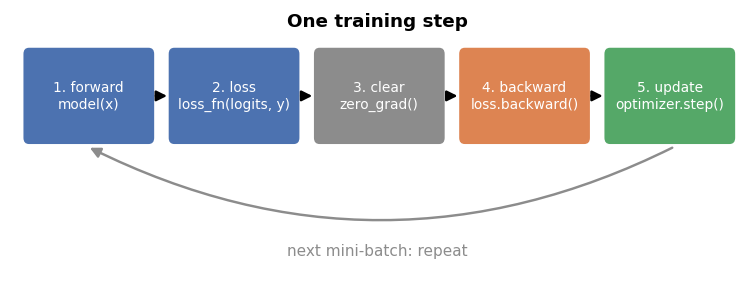

In [ ]:
def make_moons(n=1000, noise=0.15, seed=0):
    # Two interleaving half-circles: a classic toy problem that a linear model cannot solve.
    g = torch.Generator().manual_seed(seed)
    n1 = n // 2
    t1, t2 = torch.rand(n1, generator=g) * math.pi, torch.rand(n - n1, generator=g) * math.pi
    upper = torch.stack([torch.cos(t1), torch.sin(t1)], dim=1)
    lower = torch.stack([1 - torch.cos(t2), 0.5 - torch.sin(t2)], dim=1)
    X = torch.cat([upper, lower]) + noise * torch.randn(n, 2, generator=g)
    y = torch.cat([torch.zeros(n1), torch.ones(n - n1)]).long()
    return X, y

set_seed(0)
X, y = make_moons()                                # X: (1000, 2) inputs, y: (1000,) labels   -> Ch. 1
model = nn.Sequential(                             # an MLP: 2 -> 32 -> 32 -> 2               -> Ch. 4
    nn.Linear(2, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 2),                              # 2 outputs = one score ("logit") per class
)
loss_fn = nn.CrossEntropyLoss()                    # softmax + negative log-likelihood          -> Ch. 5
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)   # the update rule (Adam)           -> Ch. 3

for step in range(300):                            # full batch: every step uses all 1,000 points
    logits = model(X)                              # 1. forward pass
    loss = loss_fn(logits, y)                      # 2. compute the loss
    optimizer.zero_grad()                          # 3. clear old gradients                     -> Ch. 2
    loss.backward()                                # 4. backpropagation: compute all gradients -> Ch. 2
    optimizer.step()                               # 5. update every parameter
    if step % 100 == 0:
        print(f"step {step:3d}  loss {loss.item():.4f}")

with torch.no_grad():                              # no gradients needed for evaluation        -> Ch. 2
    accuracy = (model(X).argmax(dim=1) == y).float().mean()
print(f"training accuracy: {accuracy.item():.1%}")

In [ ]:
# Visualize what the network learned: color every point of a grid by the predicted class.
xx, yy = torch.meshgrid(torch.linspace(-1.5, 2.5, 200), torch.linspace(-1.0, 1.5, 200), indexing="xy")
grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)           # (40000, 2)
with torch.no_grad():
    pred = model(grid).argmax(dim=1).reshape(xx.shape)

plt.figure(figsize=(6, 3.5))
plt.contourf(xx, yy, pred, alpha=0.3, cmap="coolwarm")
plt.scatter(X[:, 0], X[:, 1], c=y, s=6, cmap="coolwarm")
plt.title("Decision regions learned by the MLP"); plt.show()

The five lines inside the loop (**forward, loss, zero_grad, backward, step**) are the heart of every PyTorch training script. Only the model, the data and the bookkeeping around the loop change.

| In the code | Concept | Chapter |
| --- | --- | --- |
| `X`, `y`, `grid` | Tensors | 1 |
| `backward()`, `zero_grad()`, `no_grad()` | Autograd | 2 |
| `optimizer.step()` | Optimizers | 3 |
| `nn.Sequential`, `nn.Linear` | Modules | 4 |
| `CrossEntropyLoss`, `argmax` | Losses and predictions | 5 |
| *missing:* mini-batches, validation data | Data | 6 |
| *missing:* honest evaluation | Project | 7 |

⚠️ The script reports accuracy **on its own training data**, which says little about new data. Chapter 7 fixes this.

---
# Chapter 1. Tensors

🎯 Create tensors with the right dtype; read and change shapes; index, broadcast and reduce; multiply matrices; use the GPU.

A **tensor** is an n-dimensional array of numbers of one type. The API is close to NumPy. PyTorch adds three things: a **device** (CPU or GPU), **automatic differentiation** (Chapter 2), and **16-bit number formats** for speed.

| Rank (`ndim`) | Example shape | Typical meaning |
| --- | --- | --- |
| 0 | `()` | a loss value |
| 1 | `(10,)` | a bias vector; the labels of 10 examples |
| 2 | `(64, 784)` | 64 flattened 28×28 images, **one row per example** |
| 4 | `(64, 3, 32, 32)` | 64 color images, **(N, C, H, W)** = batch, channels, height, width |

**Convention:** dimension 0 is the **batch**. Most bugs are shape bugs, so **print shapes** often.

## 1.1 Creating tensors

In [ ]:
a = torch.tensor([[1.0, 2.0, 3.0],
                  [4.0, 5.0, 6.0]])          # from a nested Python list
print(a)
print("shape:", a.shape, "| ndim:", a.ndim, "| numel:", a.numel())
print("dtype:", a.dtype, "| device:", a.device)

`a.shape` behaves like a tuple; `a.numel()` is the number of elements. The common **factory functions**:

In [ ]:
print(torch.zeros(2, 3))                    # all zeros, shape (2, 3)
print(torch.ones(2, 3))
print(torch.full((2, 2), 7.0))              # every entry 7.0
print(torch.arange(0, 10, 2))               # 0, 2, 4, 6, 8 : like range(), the end is excluded
print(torch.linspace(0, 1, 5))              # 5 evenly spaced points, both ends included
print(torch.eye(3))                         # 3x3 identity matrix
print(torch.rand(2, 3))                     # uniform random numbers in [0, 1)
print(torch.randn(2, 3))                    # standard normal N(0, 1): used to initialize weights
print(torch.randint(0, 10, (5,)))           # 5 random integers in [0, 10): fake class labels
print(torch.zeros_like(a))                  # same shape, dtype and device as `a`

### dtypes
| dtype | Alias | Use |
| --- | --- | --- |
| `torch.float32` | `torch.float` | inputs, weights, activations, losses (**PyTorch's default**) |
| `torch.int64` | `torch.long` | class labels and indices |
| `torch.bool` | | masks such as `x > 0` |
| `torch.float64` | `torch.double` | high-precision checks (**NumPy's default**) |

NumPy data is `float64`, PyTorch layers are `float32`. Mixing them is the classic first-week error:

In [ ]:
x_np = np.random.rand(4, 3)                  # NumPy: float64
layer = nn.Linear(3, 2)                      # PyTorch layer: float32 weights
print("numpy dtype:", x_np.dtype, "| layer dtype:", layer.weight.dtype)

try:
    layer(torch.from_numpy(x_np))            # float64 input into a float32 layer
except RuntimeError as e:
    print("RuntimeError:", e)

x = torch.from_numpy(x_np).float()           # the fix: convert ONCE, where NumPy data enters PyTorch
print("works:", layer(x).shape)

Convert with `.float()`, `.long()`, `.bool()` or `.to(dtype)`. Note that `/` always returns a float (`torch.tensor(7) / 2` is `3.5`), while `//` is integer division.

**Copy or share?** `torch.tensor(array)` **copies**. `torch.from_numpy(array)` and `tensor.numpy()` **share memory** on the CPU: changing one changes the other.

In [ ]:
arr = np.zeros(3)
shared = torch.from_numpy(arr)
copied = torch.tensor(arr)
arr[0] = 42.0                    # modify the NumPy array
print("shared:", shared)         # sees the change
print("copied:", copied)         # does not

## 1.2 Changing shape
Reshaping preserves element values but may return a view **or a copy**, depending on strides. Ordinary **contiguous** tensors use row-major layout (last index changes fastest); transposed/permuted tensors need not be contiguous. A shape is not a guarantee of memory layout.

| Operation | What it does | Typical use |
| --- | --- | --- |
| `x.reshape(2, -1)` | same elements, new shape; `-1` = "work it out" | general |
| `x.flatten(start_dim=1)` | merge all dims from `start_dim` on | `(N, 1, 28, 28) → (N, 784)` |
| `x.unsqueeze(d)` / `x.squeeze(d)` | insert / remove a size-1 dim at `d` | add a batch dim; `(N, 1) → (N,)` |
| `x.permute(…)` | reorder dims | `(H, W, C) → (C, H, W)` |
| `x.T`, `x.transpose(i, j)` | swap two dims | matrix transpose |

🤔 **Predict** the shapes printed by the next cell.

In [ ]:
x = torch.arange(12)                  # tensor([0, 1, ..., 11]), shape (12,)
print(x.reshape(3, 4))                # rows filled in order: [0..3], [4..7], [8..11]
print(x.reshape(2, -1).shape)         # -1 is inferred: 12 / 2 = 6
print(x.reshape(2, 3, 2).shape)

imgs = torch.randn(8, 1, 28, 28)      # a batch of 8 grayscale images, (N, C, H, W)
print("flatten(start_dim=1):", imgs.flatten(start_dim=1).shape)   # keep N, merge the rest
print("flatten():           ", imgs.flatten().shape)              # merges the batch too: usually a bug!

In [ ]:
one_image = torch.randn(1, 28, 28)                 # a single image, (C, H, W)
batch = one_image.unsqueeze(0)                     # models always expect a batch dimension
print("unsqueeze(0):", one_image.shape, "->", batch.shape)
print("same thing with None indexing:", one_image[None].shape)

preds = torch.randn(5, 1)                          # e.g. a regression model's output
print("squeeze(1):", preds.shape, "->", preds.squeeze(1).shape)

photo = torch.rand(32, 32, 3)                      # how image files are stored: (H, W, C)
chw = photo.permute(2, 0, 1)                       # new order: old dim 2, then old 0, then old 1
print("permute(2, 0, 1):", photo.shape, "->", chw.shape)

⚠️ **`reshape` is not `permute`.** Both turn `(32, 32, 3)` into `(3, 32, 32)`, but only `permute` keeps each pixel's colors together. `reshape` re-cuts the flat sequence and scrambles the image:

In [ ]:
# A 2x2 "image" with 3 channels, stored (H, W, C). The value encodes the channel: 0.x = R, 1.x = G, 2.x = B
img = torch.tensor([[[0.0, 1.0, 2.0], [0.1, 1.1, 2.1]],
                    [[0.2, 1.2, 2.2], [0.3, 1.3, 2.3]]])
print("permute -> channel 0 should hold only 0.x values:\n", img.permute(2, 0, 1)[0])
print("reshape -> channel 0 is a mixture (wrong):\n", img.reshape(3, 2, 2)[0])

You will also see `x.view(...)`. It is like `reshape` but refuses some tensors (for example right after a transpose); Notebook 2's appendix explains why. Prefer `reshape`.

## 1.3 Indexing
Indexing works like NumPy: one index or slice per dimension.

In [ ]:
x = torch.arange(12).reshape(3, 4)
print(x)
print("x[1]        ->", x[1])              # row 1 (the second row)
print("x[1, 2]     ->", x[1, 2])           # a 0-d tensor; use .item() to get a Python number
print("x[:, 2]     ->", x[:, 2])           # column 2, from every row
print("x[:, -1]    ->", x[:, -1])          # the last column
print("x[0:2, 1:3] ->\n", x[0:2, 1:3])     # rows 0-1, columns 1-2
print("x[[0, 2]]   ->\n", x[[0, 2]])       # a list of indices picks those rows

**Boolean masks** select the elements where a condition holds:

In [ ]:
x = torch.arange(12).reshape(3, 4)
mask = x > 5
print(mask)
print("x[mask]:", x[mask])              # a 1-D tensor of the selected values
print("how many > 5:", mask.sum().item())

y = x.clone()                           # clone() makes an independent copy
y[y % 2 == 0] = -1                      # assign through a mask
print(y)

**One entry per row.** To pick, for each example, the probability of its **correct** class, index with two equal-length tensors: one for rows, one for columns.

In [ ]:
probs = torch.tensor([[0.7, 0.2, 0.1],
                      [0.1, 0.8, 0.1],
                      [0.3, 0.3, 0.4],
                      [0.5, 0.4, 0.1]])
labels = torch.tensor([0, 1, 0, 1])                 # correct class of each example

p_correct = probs[torch.arange(4), labels]          # rows 0,1,2,3 paired with columns 0,1,0,1
print("probability of the correct class:", p_correct)   # tensor([0.7, 0.8, 0.3, 0.4])
print("cross-entropy by hand:", -torch.log(p_correct).mean())

You just computed cross-entropy by hand. Other code writes the same selection as `probs.gather(1, labels.unsqueeze(1))`.

## 1.4 Broadcasting
An elementwise operation on tensors of **different shapes** stretches size-1 dimensions so the shapes match, without copying the inputs.

**Rule:** align the shapes **from the right**. Each pair of sizes must be equal, or one of them must be 1. A missing dimension counts as 1.

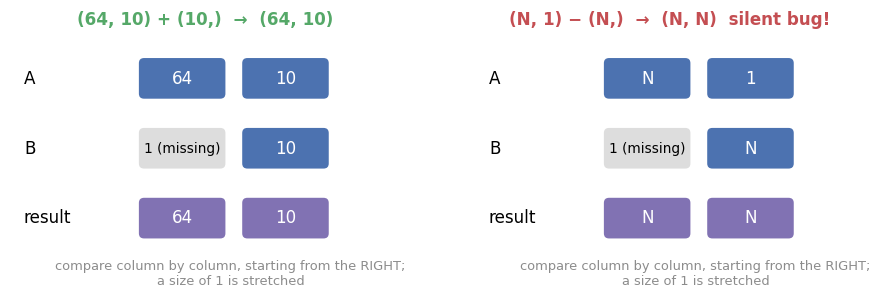

A bias is added by broadcasting: `X @ W.T + b` adds `b` of shape `(out,)` to every row of an `(N, out)` matrix.

In [ ]:
X = torch.randn(5, 3)                                 # 5 examples, 3 features
b = torch.tensor([10.0, 20.0, 30.0])                  # one value per feature
print((X + b).shape)                                  # (5, 3): b added to every row

# Standardize every feature (column) to mean 0, std 1.
mean = X.mean(dim=0, keepdim=True)                    # (1, 3): one mean per column (see 1.5)
std = X.std(dim=0, keepdim=True)                      # (1, 3); note: divides by N-1 (NumPy's np.std divides by N)
Xs = (X - mean) / std                                 # (5, 3) op (1, 3) -> (5, 3)
print("column means:", Xs.mean(dim=0))                # approx. 0
print("column stds: ", Xs.std(dim=0))                 # approx. 1

# The "outer" pattern: (3, 1) op (1, 4) -> (3, 4), every combination
rows = torch.tensor([[1.0], [2.0], [3.0]])
cols = torch.tensor([[10.0, 20.0, 30.0, 40.0]])
print(rows * cols)

⚠️ **The `(N, 1)` vs `(N,)` bug.** A regression model outputs `(N, 1)`; targets loaded from a file are often `(N,)`. Their difference broadcasts to `(N, N)`: every prediction is compared with every target. Training runs, the loss is finite, and the model learns almost nothing.

🤔 **Predict** the shape of `pred - y`.

In [ ]:
N = 4
pred = torch.randn(N, 1)       # model output: (N, 1)
y = torch.randn(N)             # targets:      (N,)
print("pred - y has shape", (pred - y).shape)            # (4, 4), not (4,)!

wrong = ((pred - y) ** 2).mean()                         # silently wrong
right = ((pred.squeeze(1) - y) ** 2).mean()              # make the shapes equal first
print(f"wrong loss: {wrong:.3f}   right loss: {right:.3f}")

**Defense:** assert shapes where data meets the model or the loss, e.g. `assert pred.shape == y.shape`.

## 1.5 Reductions and `dim`
`sum`, `mean`, `max`, `std`, `argmax` collapse a dimension. **The `dim` you name is the one that disappears.** For a `(examples, features)` matrix, `x.sum(dim=0)` gives one value per feature and `x.sum(dim=1)` one value per example. `keepdim=True` keeps it with size 1, so the result still broadcasts against `x`.

In [ ]:
x = torch.tensor([[1.0, 5.0, 3.0],
                  [4.0, 2.0, 6.0]])               # shape (2, 3)
print("x.sum()              =", x.sum())               # everything -> a scalar
print("x.sum(dim=0)         =", x.sum(dim=0))          # (3,): one per column
print("x.sum(dim=1)         =", x.sum(dim=1))          # (2,): one per row
print("x.sum(dim=1, keepdim=True).shape =", x.sum(dim=1, keepdim=True).shape)   # (2, 1)

values, indices = x.max(dim=1)                     # max along a dim returns BOTH
print("max of each row:", values, "found at column", indices)
print("argmax(dim=1):  ", x.argmax(dim=1))         # how logits become predicted classes

From logits to accuracy, a pattern you will write in every classification project:

In [ ]:
logits = torch.tensor([[2.0, 0.5, -1.0],     # model scores, shape (N=4, C=3)
                       [0.1, 0.2,  3.0],
                       [1.0, 2.0,  0.0],
                       [0.3, 0.1,  0.2]])
labels = torch.tensor([0, 2, 0, 0])

predicted = logits.argmax(dim=1)              # (4,): the class with the highest score in each row
correct = (predicted == labels)               # (4,) booleans
print("predicted:", predicted, "| correct:", correct)
print("accuracy:", correct.float().mean().item())   # bool -> float, then average

## 1.6 Combining and selecting

| Function | What it does |
| --- | --- |
| `torch.cat([a, b], dim=d)` | join along an **existing** dim |
| `torch.stack([a, b], dim=d)` | join equal-shape tensors along a **new** dim |
| `torch.where(cond, a, b)` | elementwise: `a` where `cond`, else `b` |
| `x.masked_fill(mask, v)` | copy of `x` with `v` where `mask` is true |
| `x.topk(k, dim)` / `x.argsort(dim)` | the `k` largest values and their indices / the sorting order |

🤔 **Predict** the four shapes printed by the first lines of the next cell.

In [ ]:
a, b = torch.zeros(2, 3), torch.ones(4, 3)
print("cat dim=0:  ", torch.cat([a, b], dim=0).shape)                 # (6, 3): more rows
print("cat dim=1:  ", torch.cat([a, torch.ones(2, 5)], dim=1).shape)  # (2, 8): more columns
p, q = torch.zeros(2, 3), torch.ones(2, 3)
print("stack dim=0:", torch.stack([p, q], dim=0).shape)              # (2, 2, 3): a new leading dimension
print("stack dim=2:", torch.stack([p, q], dim=2).shape)              # (2, 3, 2): a new last dimension

# stack is what a DataLoader does to build a batch: 4 examples of shape (1, 28, 28) -> (4, 1, 28, 28)
examples = [torch.randn(1, 28, 28) for _ in range(4)]
print("a batch:    ", torch.stack(examples).shape)

In [ ]:
x = torch.tensor([[-2.0, 0.5, 3.0],
                  [1.0, -0.5, -4.0]])
print("where(x > 0, x, 0):\n", torch.where(x > 0, x, 0.0))      # ReLU written by hand
print("masked_fill(x < 0, -1):\n", x.masked_fill(x < 0, -1.0))

# A very common pattern: forbid some options by setting their logits to -inf before a softmax
logits = torch.tensor([[2.0, 1.0, 0.5, 3.0]])
allowed = torch.tensor([[True, True, True, False]])                  # option 3 is not allowed here
print("softmax with option 3 masked out:", torch.softmax(logits.masked_fill(~allowed, float("-inf")), dim=1))

In [ ]:
scores = torch.tensor([[0.1, 0.5, 0.3, 0.9, 0.2],
                       [0.8, 0.1, 0.6, 0.0, 0.4]])
values, indices = scores.topk(3, dim=1)            # the 3 best classes of each row, best first
print("top-3 values: ", values)
print("top-3 classes:", indices)
print("full ranking: ", scores.argsort(dim=1, descending=True))

labels = torch.tensor([1, 4])
in_top3 = (indices == labels[:, None]).any(dim=1)  # broadcasting (N, 3) == (N, 1)
print("top-3 accuracy:", in_top3.float().mean().item())   # common on ImageNet-style benchmarks

## 1.7 Elementwise vs matrix multiplication
- `A * B`: elementwise (Hadamard) product, with broadcasting.
- `A @ B`: matrix product, `(n, k) @ (k, m) → (n, m)`. With more than 2 dims, the leading dims are a batch.

`nn.Linear(in, out)` stores `W` with shape **`(out, in)`** and computes `x @ W.T + b`:

In [ ]:
lin = nn.Linear(3, 2)                       # 3 inputs -> 2 outputs
x = torch.randn(5, 3)                       # a batch of 5 examples
print("weight:", lin.weight.shape, "| bias:", lin.bias.shape)    # (2, 3) and (2,)

by_hand = x @ lin.weight.T + lin.bias       # (5,3) @ (3,2) -> (5,2), plus (2,) broadcast to every row
print("output:", lin(x).shape, "| matches by hand:", torch.allclose(lin(x), by_hand))

A = torch.randn(10, 4, 5)                   # a batch of 10 matrices, each 4x5
B = torch.randn(10, 5, 6)
print("batched matmul:", (A @ B).shape)     # (10, 4, 6)

Compare floats with `torch.allclose`, never `==`: the same maths computed in a different order differs in the last bits.

## 1.8 Devices: CPU and GPU
1. Move with `.to(device)`.
2. All tensors in one operation must be on the **same device**, otherwise: *"Expected all tensors to be on the same device"*.
3. CPU ↔ GPU copies are slow. Keep work on the GPU; bring back a number with `.item()` or a tensor with `.cpu()`.

In [ ]:
x_cpu = torch.randn(3, 3)
x_dev = x_cpu.to(device)
print("x_dev lives on:", x_dev.device)

if device.type != "cpu":
    try:
        x_cpu + x_dev                               # mixed devices
    except RuntimeError as e:
        print("RuntimeError:", str(e)[:95], "...")

y = torch.zeros(3, 3, device=device)                # or create a tensor directly on the device
loss = ((x_dev - y) ** 2).mean()
print("a Python float:", loss.item())               # 1-element tensor -> Python number
print("a NumPy array:\n", x_dev.cpu().numpy())      # GPU tensors must come to the CPU before .numpy()

A GPU runs the same operation on thousands of numbers in parallel, and networks are mostly matrix multiplications.

⚠️ **Timing GPU code.** GPU work is **asynchronous**: Python queues it and moves on. Call `sync()` (our helper around `torch.cuda.synchronize()`) before reading the clock, and do a warm-up run first.

In [ ]:
def time_matmul(dev, n=2048, reps=10):
    a, b = torch.randn(n, n, device=dev), torch.randn(n, n, device=dev)
    a @ b                                            # warm-up
    sync(dev)
    t0 = time.perf_counter()
    for _ in range(reps):
        a @ b
    sync(dev)                                        # wait for the GPU to actually finish
    return (time.perf_counter() - t0) / reps

t_cpu = time_matmul(torch.device("cpu"))
print(f"CPU: {t_cpu * 1e3:8.2f} ms per 2048x2048 matrix multiplication")
if device.type != "cpu":
    t_gpu = time_matmul(device)
    print(f"GPU: {t_gpu * 1e3:8.2f} ms  (about {t_cpu / t_gpu:.0f}x faster)")

## 1.9 In-place operations
Methods ending in `_` (`x.add_(1)`, `x.zero_()`), as well as `x += 1` and `x[idx] = v`, modify a tensor **in place**. They save memory but can destroy values autograd needs (Chapter 2). Default to the out-of-place versions.

In [ ]:
x = torch.ones(3)
y = x.add(1)        # new tensor; x unchanged
print("after add: ", x, y)
x.add_(1)           # x itself is modified
print("after add_:", x)

## 📖 Code-reading drill
```python
feats = torch.randn(32, 3, 8, 8)
out = feats.flatten(2).mean(-1)
```
**(a)** Shape of `feats.flatten(2)`? **(b)** Shape of `out`, and what does each number mean? Answer on paper, then run the cell.

In [ ]:
feats = torch.randn(32, 3, 8, 8)
print(feats.flatten(2).shape, feats.flatten(2).mean(-1).shape)
# (a) (32, 3, 64): every dimension from 2 on (8x8) is merged.
# (b) (32, 3): the average value of each channel of each image.
#     dim=-1 means "the last dimension"; negative dims count from the end.
#     This is "global average pooling", which you will meet again with CNNs in Notebook 2.

## 🧪 Exercises
**Exercise 1.1: pairwise squared distances.** `★★☆ · 15 min`
Write `pairwise_sq_dists(A, B)` for `A` `(n, d)` and `B` `(m, d)` returning `D` `(n, m)` with `D[i, j] = ‖A[i] − B[j]‖²`. Use broadcasting, no loops. (This is the core of k-nearest-neighbors.)

In [ ]:
# ✍️ Your attempt here.
# Hint: A[:, None, :] has shape (n, 1, d) and B[None, :, :] has shape (1, m, d).

In [ ]:
# 🔎 Self-check for Exercise 1.1 (tests YOUR function)
def _test(fn):
    A, B = torch.randn(5, 3), torch.randn(7, 3)
    D = fn(A, B)
    assert D.shape == (5, 7), f"shape {tuple(D.shape)}, expected (5, 7)"
    loop = torch.tensor([[((a - b) ** 2).sum().item() for b in B] for a in A])
    assert torch.allclose(D, loop, atol=1e-5), "values differ from a Python-loop reference"
self_check("pairwise_sq_dists", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def pairwise_sq_dists(A, B):
        diff = A[:, None, :] - B[None, :, :]     # (n, 1, d) - (1, m, d) -> (n, m, d)
        return (diff ** 2).sum(dim=-1)           # sum over d -> (n, m)

    A, B = torch.randn(5, 3), torch.randn(7, 3)
    print(pairwise_sq_dists(A, B).shape)
    # Memory note: the intermediate (n, m, d) tensor can be huge for big n, m.
    # The identity ||a-b||² = ||a||² + ||b||² - 2 a·b avoids it, and torch.cdist(A, B) ** 2 does it for you.
    print(torch.allclose(pairwise_sq_dists(A, B), torch.cdist(A, B) ** 2, atol=1e-5))
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 1.2: a numerically stable softmax.** `★★☆ · 15 min`
`softmax(z)_k = exp(z_k) / Σ_j exp(z_j)` overflows for `z = 1000`. Write `softmax_stable(z, dim)` using `softmax(z) = softmax(z − c)`: subtract the maximum along `dim`.

In [ ]:
# ✍️ Your attempt here.
# Hint: z.max(dim=dim, keepdim=True).values keeps the dimension, so it broadcasts.

In [ ]:
# 🔎 Self-check for Exercise 1.2 (tests YOUR function)
def _test(fn):
    z = torch.tensor([[1000.0, 1001.0, 1002.0], [-5.0, 0.0, 5.0]])
    s = fn(z, dim=1)
    assert torch.isfinite(s).all(), "result contains inf or nan"
    assert torch.allclose(s, torch.softmax(z, dim=1), atol=1e-6), "values differ from torch.softmax"
    z2 = torch.randn(4, 6)
    assert torch.allclose(fn(z2, dim=0), torch.softmax(z2, dim=0), atol=1e-6), "wrong along dim=0"
self_check("softmax_stable", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def softmax_stable(z, dim):
        z = z - z.max(dim=dim, keepdim=True).values      # largest entry becomes 0 -> no overflow
        e = torch.exp(z)
        return e / e.sum(dim=dim, keepdim=True)           # keepdim=True so the division broadcasts

    print(softmax_stable(torch.tensor([[1000.0, 1001.0, 1002.0]]), dim=1))
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 1.3: preparing a batch of images.** `★★☆ · 15 min`
Images load as `uint8` in `(N, H, W, C)` with values 0–255. Write `prepare_batch(x, mean, std)` returning `float32` `(x / 255 − mean) / std` in layout `(N, 3, H, W)`, where `mean` and `std` are lists of 3 numbers.

In [ ]:
# ✍️ Your attempt here.
# Hint: permute(0, 3, 1, 2) first; reshape mean and std to (1, 3, 1, 1).

In [ ]:
# 🔎 Self-check for Exercise 1.3 (tests YOUR function)
def _test(fn):
    x = torch.randint(0, 256, (2, 4, 5, 3), dtype=torch.uint8)
    out = fn(x, [0.5, 0.4, 0.3], [0.2, 0.25, 0.3])
    assert out.shape == (2, 3, 4, 5), f"shape {tuple(out.shape)}, expected (2, 3, 4, 5)"
    assert out.dtype == torch.float32, f"dtype {out.dtype}, expected float32"
    ref = (x[1, 2, 3, 1].item() / 255 - 0.4) / 0.25
    assert abs(out[1, 1, 2, 3].item() - ref) < 1e-5, "values look wrong (check the channel order)"
self_check("prepare_batch", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def prepare_batch(x, mean, std):
        x = x.permute(0, 3, 1, 2).float() / 255.0                  # (N, 3, H, W), values in [0, 1]
        mean = torch.tensor(mean, dtype=torch.float32).reshape(1, 3, 1, 1)   # broadcastable shapes
        std = torch.tensor(std, dtype=torch.float32).reshape(1, 3, 1, 1)
        return (x - mean) / std

    print(prepare_batch(torch.randint(0, 256, (2, 4, 5, 3), dtype=torch.uint8), [0.5] * 3, [0.25] * 3).shape)
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- A tensor has a **shape**, a **dtype** and a **device**; most errors are a mismatch in one of them.
- Continuous data `float32`, labels `int64`; convert NumPy data with `.float()`.
- In a reduction, the `dim` you name disappears; `keepdim=True` keeps it for broadcasting.
- Broadcasting aligns from the right: `(N, 1)` with `(N,)` silently gives `(N, N)`.
- `nn.Linear` computes `x @ W.T + b` with `W` of shape `(out, in)`.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** Shape of `torch.randn(64, 3, 32, 32).mean(dim=(2, 3))`, and its meaning?

<details>
<summary>Answer</summary>

`(64, 3)`: the mean of each channel of each image.

</details>

**2.** `a` is `(8, 1)` and `b` is `(8,)`. Shape of `a + b`?

<details>
<summary>Answer</summary>

`(8, 8)`: aligned from the right, `(8, 1)` vs `(1, 8)`, both size-1 dims are stretched.

</details>

**3.** 16 tensors of shape `(3, 32, 32)` → one batch `(16, 3, 32, 32)`: `cat` or `stack`?

<details>
<summary>Answer</summary>

`torch.stack(list, dim=0)` (new dimension). `cat` would give `(48, 32, 32)`.

</details>

**4.** Why call `sync()` / `torch.cuda.synchronize()` before stopping a timer?

<details>
<summary>Answer</summary>

GPU work is asynchronous; without it you time how long it took to *queue* the work.

</details>

---
# Chapter 2. Autograd: backpropagation, done for you

🎯 Compute gradients with `backward()`; explain what autograd records; avoid the accumulation and memory-leak pitfalls; switch autograd off; run gradient descent with plain tensors.

**Autograd** is PyTorch's implementation of backpropagation. Operations on tensors with `requires_grad=True` are recorded; `loss.backward()` walks that record backwards with the chain rule and stores each gradient in the `.grad` attribute of the tensors you asked about.

## 2.1 A hand calculation, checked by autograd
One input, one sigmoid hidden unit, one sigmoid output, squared error:

$$z_1 = w_1 x + b_1,\quad a_1 = \sigma(z_1),\quad z_2 = w_2 a_1 + b_2,\quad a_2 = \sigma(z_2),\quad L = \tfrac12 (a_2 - y)^2$$

with $w_1 = 0.5,\ b_1 = 0.1,\ w_2 = 0.8,\ b_2 = -0.3,\ x = 2,\ y = 1$ and $\sigma'(z) = \sigma(z)(1 - \sigma(z))$.

**Forward:** $z_1 = 1.1$, $a_1 = 0.7503$, $z_2 = 0.3002$, $a_2 = 0.5745$, $L = 0.0905$.

**Backward:**

| Quantity | Formula | Value |
| --- | --- | --- |
| $\delta_2 = \partial L/\partial z_2$ | $(a_2 - y)\, a_2 (1 - a_2)$ | $-0.1040$ |
| $\partial L/\partial w_2$, $\partial L/\partial b_2$ | $\delta_2 a_1$, $\delta_2$ | $-0.0780$, $-0.1040$ |
| $\delta_1 = \partial L/\partial z_1$ | $\delta_2 w_2\, a_1 (1 - a_1)$ | $-0.0156$ |
| $\partial L/\partial w_1$, $\partial L/\partial b_1$ | $\delta_1 x$, $\delta_1$ | $-0.0312$, $-0.0156$ |

The code below is the same five equations, written with tensors:

In [ ]:
# Parameters: the tensors we want gradients for -> requires_grad=True
w1 = torch.tensor(0.5, requires_grad=True)
b1 = torch.tensor(0.1, requires_grad=True)
w2 = torch.tensor(0.8, requires_grad=True)
b2 = torch.tensor(-0.3, requires_grad=True)
x, y = torch.tensor(2.0), torch.tensor(1.0)        # data: we do not need gradients for these

# Forward pass: autograd records every operation as it happens
z1 = w1 * x + b1
a1 = torch.sigmoid(z1)
z2 = w2 * a1 + b2
a2 = torch.sigmoid(z2)
L = 0.5 * (a2 - y) ** 2
print(f"forward: z1={z1.item():.4f}  a1={a1.item():.4f}  z2={z2.item():.4f}  a2={a2.item():.4f}  L={L.item():.4f}")

L.backward()          # backward pass: fills .grad of every tensor created with requires_grad=True

for name, p in [("w2", w2), ("b2", b2), ("w1", w1), ("b1", b1)]:
    print(f"dL/d{name} = {p.grad.item():+.4f}")

The numbers match the table. You will rarely differentiate by hand again, but you must know **what** autograd computes to debug it.

## 2.2 The computational graph

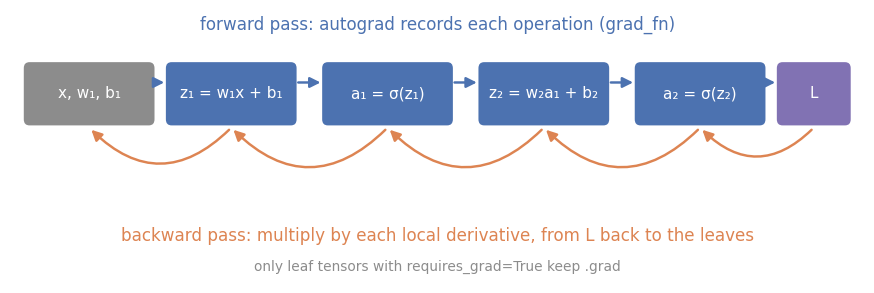

- A **leaf** is a tensor you created directly (parameters are leaves).
- Each result of an operation gets a **`grad_fn`** that knows its local derivative and points to its inputs' `grad_fn`s: the **graph**.
- `.grad` is kept **only for leaves** with `requires_grad=True`. Intermediate gradients are used and discarded (use `t.retain_grad()` before `backward()` if you need one).

In [ ]:
print("L.grad_fn        :", L.grad_fn)                   # the last operation: multiplication by 0.5
print("its inputs       :", L.grad_fn.next_functions)    # links back toward the start of the graph
print("w1 is a leaf?    :", w1.is_leaf, "| a1 is a leaf?", a1.is_leaf)
print("a1.grad          :", a1.grad)                     # None: intermediate gradients are not kept
print("x.requires_grad  :", x.requires_grad)             # data does not need gradients

(Reading `a1.grad` also prints a warning saying the same thing.)

**The graph is rebuilt on every forward pass** ("define-by-run"), so ordinary Python `if` and loops work inside models; the gradient follows the branch that actually ran:

In [ ]:
def f(x):
    if x > 0:                      # plain Python control flow
        return x ** 2              # derivative 2x
    return -3 * x                  # derivative -3

for value in (2.0, -1.0):
    x = torch.tensor(value, requires_grad=True)
    f(x).backward()
    print(f"x = {value:+.0f}: gradient = {x.grad.item()}")

## 2.3 Gradients accumulate: why `zero_grad()` exists
🤔 **Predict:** $d(w^2)/dw = 6$ at $w = 3$. What does the cell print after three `backward()` calls?

In [ ]:
w = torch.tensor(3.0, requires_grad=True)
for step in range(3):
    loss = w ** 2
    loss.backward()
    print(f"after backward #{step + 1}: w.grad = {w.grad.item()}")

**`backward()` adds to `.grad`; it never overwrites.** This is deliberate: it lets you sum gradients over several small batches (gradient accumulation, Notebook 2). So you must **clear gradients before each step**. `optimizer.zero_grad()` does this by setting every `.grad` to `None`, as below:

In [ ]:
w.grad = None              # what optimizer.zero_grad() does for every parameter
(w ** 2).backward()
print("after clearing:", w.grad.item())

## 2.4 Two rules of `backward()`
**Rule 1: `loss.backward()` without arguments needs a scalar.** A gradient $\partial L/\partial w$ is defined for one number $L$. For a non-scalar output you must say how to combine its entries: `out.backward(gradient=v)` computes $v^\top\, \partial\,\text{out}/\partial w$ (a *vector–Jacobian product*). With `v` all ones this is the gradient of `out.sum()`, which is why `out.sum().backward()` is a common idiom.

**Rule 2: a graph can be back-propagated through once.** The values saved for the backward pass are freed when `backward()` finishes. A training loop builds a new graph every step, so this is never a problem there. (`backward(retain_graph=True)` keeps them, rarely needed.)

In [ ]:
v = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
out = v ** 2                                   # a vector, not a scalar
try:
    out.backward()
except RuntimeError as e:
    print("Rule 1 -> RuntimeError:", e)
out.sum().backward()                           # reduce to a scalar first
print("d(sum of v²)/dv =", v.grad)             # 2v

v.grad = None
out = v ** 2
out.backward(gradient=torch.ones_like(out))    # vector-Jacobian product with a vector of ones
print("backward(gradient=ones) gives the same:", v.grad)

w = torch.tensor(3.0, requires_grad=True)
loss = w ** 2
loss.backward()
try:
    loss.backward()                            # second backward through the same graph
except RuntimeError as e:
    print("Rule 2 -> RuntimeError:", str(e)[:100], "...")

## 2.5 Switching autograd off
Recording costs memory and time. Switch it off when you do not need gradients:

| Tool | Effect | Use for |
| --- | --- | --- |
| `with torch.no_grad():` | nothing inside is recorded | evaluation, manual parameter updates |
| `with torch.inference_mode():` | like `no_grad`, slightly faster; tensors created inside cannot be used later in computations that autograd records | pure prediction |
| `t.detach()` | same data, cut out of the graph | logging, plotting, NumPy conversion |

In [ ]:
w = torch.randn(3, requires_grad=True)
y1 = w * 2
with torch.no_grad():
    y2 = w * 2
print("normal       -> requires_grad:", y1.requires_grad)   # True: recorded
print("in no_grad   -> requires_grad:", y2.requires_grad)   # False: not recorded
print("detach()     -> requires_grad:", y1.detach().requires_grad)

try:
    y1.numpy()                       # NumPy knows nothing about graphs
except RuntimeError as e:
    print("RuntimeError:", str(e)[:70], "...")
print("fix:", y1.detach().numpy())

⚠️ **The logging memory leak.** `total_loss += loss` keeps every step's graph alive and memory grows until the program crashes. Log with `total_loss += loss.item()`, a plain Python number.

## 2.6 Gradient descent with nothing but tensors
Minimize $f(w) = (w_0 - 3)^2 + 10\,(w_1 + 1)^2$ (minimum at $(3, -1)$) with $w \leftarrow w - \eta \nabla f(w)$. Note the two marked details:

In [ ]:
def gradient_descent(lr, steps=100):
    w = torch.zeros(2, requires_grad=True)
    history = []
    for _ in range(steps):
        f = (w[0] - 3) ** 2 + 10 * (w[1] + 1) ** 2
        f.backward()                       # compute the gradient into w.grad
        with torch.no_grad():              # (1) the update itself must NOT be recorded in the graph
            w -= lr * w.grad
        w.grad = None                      # (2) clear the gradient, or the next step adds to it
        history.append(f.item())
    return w.detach(), history

w_final, hist = gradient_descent(lr=0.05)
print("final w:", w_final, "| final f:", hist[-1])
plt.figure(figsize=(5, 3))
plt.semilogy(hist); plt.xlabel("step"); plt.ylabel("f(w), log scale"); plt.title("Gradient descent, lr = 0.05")
plt.show()

1. The update is inside `torch.no_grad()`: otherwise it would become part of the graph. (PyTorch refuses an in-place change to a leaf that requires grad outside `no_grad`.)
2. The gradient is cleared after each step.

This loop **is** an optimizer. Chapter 3 replaces the two marked lines with `optimizer.step()` and `optimizer.zero_grad()`.

## 2.7 In-place operations and autograd
Some backward formulas need forward values: the sigmoid's derivative needs its output. Modifying that saved output in place would give a wrong gradient, so PyTorch raises an error instead:

In [ ]:
z = torch.randn(3, requires_grad=True)
s = torch.sigmoid(z)          # autograd saves s, because the backward pass needs it
s.mul_(2)                     # in-place change to a saved tensor
try:
    s.sum().backward()
except RuntimeError as e:
    print("RuntimeError:", str(e)[:120], "...")

s = torch.sigmoid(z) * 2      # out-of-place: a new tensor, the saved one is untouched
s.sum().backward()
print("fine:", z.grad)

## 🧪 Exercises
**Exercise 2.1: a famous gradient.** `★★☆ · 15 min`
For softmax + cross-entropy, $\partial L/\partial z = \mathrm{softmax}(z) - \mathrm{onehot}(y)$ for one example; averaged over a batch of $N$, divide by $N$. Verify it: random `logits` `(8, 5)` with `requires_grad=True`, random labels, `F.cross_entropy(...).backward()`, then compare `logits.grad` with the formula using `torch.allclose`.

In [ ]:
# ✍️ Your attempt here.
# Hint: F.one_hot(labels, num_classes=5).float(); use logits.detach() inside the formula.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    logits = torch.randn(8, 5, requires_grad=True)
    labels = torch.randint(0, 5, (8,))
    F.cross_entropy(logits, labels).backward()            # mean over the batch by default

    expected = (torch.softmax(logits.detach(), dim=1) - F.one_hot(labels, 5).float()) / 8
    print("autograd matches (softmax - onehot) / N:", torch.allclose(logits.grad, expected, atol=1e-6))
    # This is why cross-entropy trains so well: the gradient is simply "predicted minus true",
    # and it never vanishes while the prediction is wrong.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 2.2: how large can the learning rate be?** `★★☆ · 15 min`
Run `gradient_descent` from §2.6 with `lr` = 0.05, 0.09, 0.1, 0.11. Which converge? Explain the threshold. *Hint:* for $f = c\,(w - w^*)^2$ one step maps $w - w^*$ to $(1 - 2c\eta)(w - w^*)$.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    for lr in (0.05, 0.09, 0.1, 0.11):
        w_final, hist = gradient_descent(lr)
        print(f"lr = {lr:<5} final w = {w_final.tolist()}  final f = {hist[-1]:.3g}")
    # Coordinate 0 has c = 1:  factor |1 - 2*lr|   < 1  <=>  lr < 1
    # Coordinate 1 has c = 10: factor |1 - 20*lr|  < 1  <=>  lr < 0.1
    # The STEEPEST direction sets the limit for all of them: lr < 0.1.
    # At lr = 0.1 the factor is exactly -1, so w1 oscillates between two values forever;
    # at lr = 0.11 it grows by 1.2x per step and diverges.
    # At lr = 0.09 both converge: w1 oscillates around -1 while shrinking (factor -0.8 per step),
    # and w0 approaches 3 smoothly (factor 0.82 per step).
    # This is ill-conditioning: one steep direction caps the step size for every direction.
    # Adaptive optimizers such as Adam (Notebook 2) are one answer to it.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 2.3: gradient checking.** `★★☆ · 20 min`
Write `numerical_grad(f, w, eps=1e-6)` returning the central finite difference $\frac{f(w + \varepsilon e_i) - f(w - \varepsilon e_i)}{2\varepsilon}$ for every entry of a 1-D `w`. Compare with autograd on `f(w) = (w.sin() * w.exp()).sum()`. Use `float64`: in `float32`, rounding swamps the small differences.

In [ ]:
# ✍️ Your attempt here.
# Hint: loop over i; w_plus = w.clone(); w_plus[i] += eps (likewise for minus).

In [ ]:
# 🔎 Self-check for Exercise 2.3 (tests YOUR function)
def _test(fn):
    w = torch.randn(5, dtype=torch.float64)
    g = fn(lambda v: (v ** 3).sum(), w)
    assert g.shape == w.shape, "the result must have the same shape as w"
    assert torch.allclose(g, 3 * w ** 2, atol=1e-5), "wrong values for f(w) = sum(w^3)"
self_check("numerical_grad", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def numerical_grad(f, w, eps=1e-6):
        g = torch.zeros_like(w)
        for i in range(w.numel()):
            w_plus, w_minus = w.clone(), w.clone()
            w_plus[i] += eps
            w_minus[i] -= eps
            g[i] = (f(w_plus) - f(w_minus)) / (2 * eps)
        return g

    f = lambda w: (w.sin() * w.exp()).sum()
    w = torch.randn(4, dtype=torch.float64, requires_grad=True)
    f(w).backward()
    num = numerical_grad(f, w.detach())
    print("autograd :", w.grad)
    print("numerical:", num)
    print("max difference:", (w.grad - num).abs().max().item())
    # PyTorch ships this check as torch.autograd.gradcheck(f, (w,)), used to test custom operations.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- `loss.backward()` fills `.grad` of the leaf tensors that have `requires_grad=True`.
- `backward()` **accumulates**: clear gradients every step.
- Use `no_grad()` for evaluation and manual updates; log with `.item()`.
- The graph is rebuilt every forward pass, so Python control flow just works.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** You call `backward()` on two mini-batches without zeroing, then `optimizer.step()`. Which gradient is used?

<details>
<summary>Answer</summary>

The **sum** of both mini-batch gradients.

</details>

**2.** Does `model.eval()` stop autograd from recording?

<details>
<summary>Answer</summary>

No. Only `no_grad()` / `inference_mode()` do. `eval()` changes layers like Dropout (Chapter 4).

</details>

**3.** Memory grows every iteration until the run crashes. First thing to check?

<details>
<summary>Answer</summary>

Whether a loss (or any tensor in the graph) is accumulated for logging without `.item()` / `.detach()`.

</details>

---
# Chapter 3. Linear regression four ways

🎯 See exactly what each abstraction replaces, and read any loop as *forward, loss, zero_grad, backward, step*.

We fit $y = 3x_1 - 2x_2 + 1 + \text{noise}$ with $\hat y = Xw + b$ and the MSE loss $J = \frac1N\sum_i(\hat y_i - y_i)^2$, automating one more piece each time. A good fit gives $w \approx (3, -2)$, $b \approx 1$.

In [ ]:
set_seed(0)
N = 200
X = torch.randn(N, 2)                                    # 200 examples, 2 features
true_w, true_b = torch.tensor([3.0, -2.0]), 1.0
y = (X @ true_w + true_b + 0.1 * torch.randn(N)).unsqueeze(1)   # shape (N, 1): see the pitfall in §1.4
print("X:", X.shape, "| y:", y.shape)

LR, STEPS = 0.1, 100
curves = {}                                              # loss history of each version, for comparison

### Version 1: everything by hand
Gradients from calculus: $\partial J/\partial w = \frac2N X^\top(\hat y - y)$, $\partial J/\partial b = \frac2N \sum_i(\hat y_i - y_i)$.

In [ ]:
w = torch.zeros(2, 1)
b = torch.zeros(1)
curves["1: by hand"] = []
for step in range(STEPS):
    y_hat = X @ w + b                       # forward pass: (N, 2) @ (2, 1) + (1,) -> (N, 1)
    err = y_hat - y
    curves["1: by hand"].append((err ** 2).mean().item())
    grad_w = 2 / N * X.T @ err              # gradient formulas, derived on paper
    grad_b = 2 / N * err.sum(dim=0)
    w -= LR * grad_w                        # update rule
    b -= LR * grad_b
print("version 1: w =", w.squeeze().tolist(), " b =", b.item())

### Version 2: autograd replaces the calculus

In [ ]:
w = torch.zeros(2, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
curves["2: autograd"] = []
for step in range(STEPS):
    loss = ((X @ w + b - y) ** 2).mean()
    curves["2: autograd"].append(loss.item())
    loss.backward()                         # <- replaces the two gradient formulas
    with torch.no_grad():
        w -= LR * w.grad
        b -= LR * b.grad
    w.grad = None
    b.grad = None
print("version 2: w =", w.detach().squeeze().tolist(), " b =", b.item())

### Version 3: an optimizer replaces the update and the clearing
For plain SGD, `step()` does `p -= lr * p.grad` inside `no_grad` for every parameter; `zero_grad()` clears the gradients.

In [ ]:
w = torch.zeros(2, 1, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
optimizer = torch.optim.SGD([w, b], lr=LR)     # the optimizer keeps references to w and b
curves["3: optimizer"] = []
for step in range(STEPS):
    loss = ((X @ w + b - y) ** 2).mean()
    curves["3: optimizer"].append(loss.item())
    optimizer.zero_grad()                     # <- replaces "w.grad = None; b.grad = None"
    loss.backward()
    optimizer.step()                          # <- replaces the no_grad update
print("version 3: w =", w.detach().squeeze().tolist(), " b =", b.item())

### Version 4: a module and a loss object replace the parameters and the formula

In [ ]:
model = nn.Linear(2, 1)
nn.init.zeros_(model.weight)                  # start from zero, like the other versions
nn.init.zeros_(model.bias)
loss_fn = nn.MSELoss()
optimizer = torch.optim.SGD(model.parameters(), lr=LR)
curves["4: module"] = []
for step in range(STEPS):
    y_hat = model(X)                          # 1. forward
    loss = loss_fn(y_hat, y)                  # 2. loss
    optimizer.zero_grad()                     # 3. clear old gradients
    loss.backward()                           # 4. backward
    optimizer.step()                          # 5. update
    curves["4: module"].append(loss.item())
print("version 4: w =", model.weight.detach().squeeze().tolist(), " b =", model.bias.item())

In [ ]:
plt.figure(figsize=(6, 3.5))
for (name, c), ls in zip(curves.items(), ["-", "--", ":", "-."]):
    plt.semilogy(c, ls, lw=2, label=name)
plt.xlabel("step"); plt.ylabel("MSE (log scale)"); plt.legend(); plt.title("Four implementations, one algorithm")
plt.show()
print("largest difference between the loss curves:",
      max(abs(a - b) for a, b in zip(curves["1: by hand"], curves["4: module"])))

The four curves coincide: **one algorithm**, four levels of automation.

| You stopped writing… | …because this does it |
| --- | --- |
| derivative formulas | `loss.backward()` |
| update rule and clearing | `optimizer.step()`, `optimizer.zero_grad()` |
| parameters with the right shapes | `nn.Linear` |
| the loss formula | `nn.MSELoss` |

Switching SGD to Adam, or a linear model to a deep network, changes **one line**; the loop stays the same.

**The canonical training step** (memorize it):
```python
pred = model(x)              # 1. forward
loss = loss_fn(pred, y)      # 2. loss
optimizer.zero_grad()        # 3. clear old gradients (anywhere before backward)
loss.backward()              # 4. compute new gradients
optimizer.step()             # 5. update parameters
```

## 🧪 Exercises
**Exercise 3.1: the shape bug, live.** `★☆☆ · 10 min`
Repeat version 4 with `y_flat = y.squeeze(1)` (shape `(N,)`) as the target. Read the warning and the learned weights. Why does the model not learn `w`?

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    y_flat = y.squeeze(1)
    bad = nn.Linear(2, 1)
    opt_bad = torch.optim.SGD(bad.parameters(), lr=LR)
    for step in range(STEPS):
        loss = F.mse_loss(bad(X), y_flat)        # (N,1) vs (N,) -> broadcast to (N,N); PyTorch warns
        opt_bad.zero_grad(); loss.backward(); opt_bad.step()
    print("w:", bad.weight.detach().squeeze().tolist(), " b:", bad.bias.item(), " mean(y):", y.mean().item())
    # Every prediction is compared with EVERY target. The best a model can do against all targets at
    # once is to predict their mean for every input, so w -> about 0 and b -> mean(y). It learns nothing about X.
    # (The F.mse_loss warning says exactly this. A hand-written loss would not even warn you.)
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 3.2: change the optimizer.** `★☆☆ · 10 min`
In version 4 use `torch.optim.Adam` with `lr=0.1`, then `lr=0.01`. Does it reach $w \approx (3, -2)$ in 100 steps? Why might Adam need a different learning rate from SGD?

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    for lr in (0.1, 0.01):
        m = nn.Linear(2, 1); nn.init.zeros_(m.weight); nn.init.zeros_(m.bias)
        opt = torch.optim.Adam(m.parameters(), lr=lr)
        for step in range(STEPS):
            loss = F.mse_loss(m(X), y)
            opt.zero_grad(); loss.backward(); opt.step()
        print(f"Adam lr={lr}: w = {[round(v, 3) for v in m.weight.detach().squeeze().tolist()]}, loss = {loss.item():.4f}")
    # Adam's step size is roughly lr in EVERY coordinate, regardless of the gradient's magnitude
    # (it divides by a running estimate of the gradient's size). With lr=0.01 and 100 steps, w can
    # move at most about 0.01 * 100 = 1 from zero, so it cannot reach 3 in time.
    # SGD's step is lr * gradient, so the two lr values mean different things. Learning rates do
    # NOT transfer between optimizers.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- autograd replaces derivatives; optimizers replace updates and clearing; modules own parameters; loss objects replace formulas.
- A learning rate only has a meaning together with its optimizer.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** What does `optimizer.step()` compute for plain SGD?

<details>
<summary>Answer</summary>

`p -= lr * p.grad` for every parameter it manages, without recording autograd history.

</details>

**2.** A loop runs `zero_grad()`, then `step()`, then `backward()`. No error. What happens?

<details>
<summary>Answer</summary>

Nothing is learned. `zero_grad()` sets `.grad` to `None`, so `step()` skips every parameter; the new gradients are wiped by the next `zero_grad()`. The loss stays flat.

</details>

---
# Chapter 4. `nn.Module`: how models are built

🎯 Write model classes; count parameters; use containers correctly; know what `train()`/`eval()` change; save and load weights.

Every layer, model and loss is an `nn.Module`. A module **finds all parameters inside it** (so `.parameters()`, `.to(device)` and `.state_dict()` work on the whole model), runs the computation in `forward`, carries a `training` flag, and can contain other modules.

## 4.1 Writing your own module

In [ ]:
class MLP(nn.Module):
    def __init__(self, in_dim=784, hidden=256, out_dim=10):
        super().__init__()                         # ALWAYS the first line: sets up the bookkeeping
        # Create every layer that has parameters HERE, once, and assign it to an attribute.
        # Assigning a module to self.<name> is what registers it.
        self.fc1 = nn.Linear(in_dim, hidden)
        self.fc2 = nn.Linear(hidden, out_dim)

    def forward(self, x):                          # x: (N, 1, 28, 28) or (N, 784)
        x = x.flatten(start_dim=1)                 # -> (N, 784)
        x = F.relu(self.fc1(x))                    # -> (N, 256)
        return self.fc2(x)                         # -> (N, 10): raw scores ("logits"), see Chapter 5

model = MLP()
print(model)                                       # the registered submodules
out = model(torch.randn(4, 1, 28, 28))             # call the model itself...
print("output shape:", out.shape)                  # ...which runs forward()

- `__init__` runs **once** and creates the layers (and their parameters). `forward` runs on **every call**. A layer created inside `forward` gets new random weights every call and never learns.
- Call `model(x)`, never `model.forward(x)`: calling the model also runs PyTorch's hooks.

## 4.2 Parameters
A `Linear` layer from $n_\text{in}$ to $n_\text{out}$ has $n_\text{in} n_\text{out} + n_\text{out}$ parameters. For 784 → 256 → 10: $(784\cdot256 + 256) + (256\cdot10 + 10) = 203{,}530$.

In [ ]:
for name, p in model.named_parameters():
    print(f"{name:12s} shape={str(tuple(p.shape)):12s} count={p.numel():>8,d}  requires_grad={p.requires_grad}")

def count_params(m: nn.Module) -> int:
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

print(f"total trainable parameters: {count_params(model):,}")
assert count_params(model) == 203_530

The names (`fc1.weight`, …) come from your attribute names and become the keys of the saved file.

**Custom learnable tensors** must be wrapped in `nn.Parameter`; a plain tensor attribute is invisible to the optimizer:

In [ ]:
class ScaledLinear(nn.Module):
    def __init__(self, d_in, d_out):
        super().__init__()
        self.linear = nn.Linear(d_in, d_out)
        self.scale = nn.Parameter(torch.ones(1))     # registered: learnable
        self.not_learned = torch.ones(1)             # plain tensor: invisible to PyTorch

    def forward(self, x):
        return self.scale * self.linear(x)

print([name for name, _ in ScaledLinear(3, 2).named_parameters()])   # 'not_learned' is missing

## 4.3 Containers
| Container | Use it when |
| --- | --- |
| `nn.Sequential(a, b, c)` | the model is a simple chain |
| `nn.ModuleList([...])` | you need a loop or custom logic in `forward` |
| `nn.ModuleDict({...})` | you need named alternatives (e.g. one head per task) |

In [ ]:
# Sequential: no forward() to write. Our MLP again, in one expression:
seq = nn.Sequential(
    nn.Flatten(),                  # module version of x.flatten(start_dim=1)
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 10),
)
print(seq)
print("seq[1] is the first Linear layer:", seq[1])
print("same parameter count as MLP:", count_params(seq))

⚠️ **A plain Python list of layers is invisible to PyTorch.** Nothing crashes, but those parameters are never trained, moved or saved:

In [ ]:
class Broken(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = [nn.Linear(10, 10) for _ in range(3)]                 # plain list: NOT registered

class Fixed(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = nn.ModuleList([nn.Linear(10, 10) for _ in range(3)])  # registered

    def forward(self, x):
        for layer in self.layers:                  # custom logic is fine with ModuleList
            x = F.relu(layer(x))
        return x

print("Broken parameter count:", count_params(Broken()))
print("Fixed parameter count: ", count_params(Fixed()))

## 4.4 Module or function?
- Layers **with parameters** (`nn.Linear`, `nn.BatchNorm1d`) must be modules created in `__init__`.
- Layers that **behave differently in training and evaluation** (`Dropout`, `BatchNorm`) should be modules, so `model.eval()` switches them.
- Stateless operations (`F.relu`, `torch.flatten`) can be either; inside `nn.Sequential` use the module form.

## 4.5 `train()` and `eval()`
`model.train()` / `model.eval()` set the `training` flag on every submodule. Of the layers used in this course, only two read it:

| Layer | `train()` mode | `eval()` mode |
| --- | --- | --- |
| `nn.Dropout(p)` | zero each value with probability `p`, scale the rest by `1/(1−p)` | identity |
| `nn.BatchNorm1d/2d` | normalize with the **batch** statistics; update running averages | normalize with the **running averages** |

In [ ]:
drop = nn.Dropout(p=0.5)
x = torch.ones(1, 8)
drop.train()
print("train mode:", drop(x))      # about half the values are 0, the rest are scaled to 2.0
drop.eval()
print("eval mode: ", drop(x))      # unchanged

BatchNorm's running averages are **buffers**: saved and moved with the model, but not trained.

In [ ]:
bn = nn.BatchNorm1d(3)
print("parameters:", [n for n, _ in bn.named_parameters()])    # weight (gamma) and bias (beta): learned
print("buffers:   ", [n for n, _ in bn.named_buffers()])       # running statistics: not learned

bn.train()
data = torch.randn(256, 3) * 5 + 10            # features with mean ~10 and std ~5
_ = bn(data)                                   # one training-mode call updates the running statistics
print("running_mean after one batch:", bn.running_mean)   # moved 10% of the way from 0 toward ~10

You will see `self.register_buffer("name", tensor)` for fixed constants that should travel with the model.

⚠️ **Evaluation needs two switches.** `eval()` changes layer behavior; `no_grad()` stops recording. They are independent:
```python
model.eval()
with torch.no_grad():
    predictions = model(x)
model.train()        # before training continues!
```

## 4.6 Moving a model to the GPU
`model.to(device)` moves all parameters and buffers **in place** (and returns the model). The input must be moved too.

In [ ]:
model = MLP().to(device)
print("model is on:", next(model.parameters()).device)     # check where a model lives
x = torch.randn(4, 1, 28, 28).to(device)                   # the data must follow
print("output:", model(x).shape, "on", model(x).device)

## 4.7 Initialization
`nn.Linear` draws its weights uniformly from $\pm 1/\sqrt{n_\text{in}}$. To use another scheme, write a function for one module and apply it to all with `model.apply(fn)`. **He initialization** (`kaiming_normal_`) is designed for ReLU networks; Notebook 2 shows why it matters for deep MLPs.

In [ ]:
def init_he(m):
    if isinstance(m, nn.Linear):                              # only touch Linear layers
        nn.init.kaiming_normal_(m.weight, nonlinearity="relu") # He initialization
        nn.init.zeros_(m.bias)

model = MLP()
model.apply(init_he)
print(f"fc1 weight std: {model.fc1.weight.std():.4f} (He target: sqrt(2/784) = {math.sqrt(2 / 784):.4f})")

## 4.8 Saving and loading weights
`model.state_dict()` maps names to tensors (all parameters and buffers). It does **not** contain the code: rebuild the architecture first, then load.

In [ ]:
model = MLP()
sd = model.state_dict()
print({k: tuple(v.shape) for k, v in sd.items()})

path = DATA_DIR / "mlp_weights.pt"
torch.save(sd, path)                                    # save the weights to a file

fresh = MLP()                                           # 1. rebuild the architecture in code
fresh.load_state_dict(torch.load(path, map_location="cpu"))   # 2. load the weights into it
x = torch.randn(2, 784)
print("same outputs after loading:", torch.allclose(model(x), fresh(x)))

`map_location="cpu"` loads GPU-saved weights on a CPU-only machine. Since PyTorch 2.6, `torch.load` uses `weights_only=True` by default, which refuses to execute code hidden in a file. A different architecture fails loudly:

In [ ]:
try:
    MLP(hidden=128).load_state_dict(sd)                 # different hidden size
except RuntimeError as e:
    print("RuntimeError:", str(e)[:230], "...")

## 📖 Code-reading drill
```python
class Block(nn.Module):
    def __init__(self, dim, p=0.1):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.ff = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(), nn.Linear(4 * dim, dim))
        self.drop = nn.Dropout(p)
        self.gamma = nn.Parameter(1e-4 * torch.ones(dim))

    def forward(self, x):                      # x: (N, dim)
        return x + self.gamma * self.drop(self.ff(self.norm(x)))
```
1. Output shape for input `(32, 64)` with `dim=64`?
2. Trainable parameters of `Block(64)`? (`nn.LayerNorm(dim)` has `2·dim`.)
3. Which parts behave differently in `eval()` mode?
4. At initialization, is the block close to the identity function? Why?

In [ ]:
class Block(nn.Module):
    def __init__(self, dim, p=0.1):
        super().__init__()
        self.norm = nn.LayerNorm(dim)
        self.ff = nn.Sequential(nn.Linear(dim, 4 * dim), nn.GELU(), nn.Linear(4 * dim, dim))
        self.drop = nn.Dropout(p)
        self.gamma = nn.Parameter(1e-4 * torch.ones(dim))

    def forward(self, x):
        return x + self.gamma * self.drop(self.ff(self.norm(x)))

blk = Block(64)
print("1.", blk(torch.randn(32, 64)).shape)
print("2.", count_params(blk), "=", 2 * 64, "+", 64 * 256 + 256, "+", 256 * 64 + 64, "+", 64)
# 3. Only the Dropout layer. (LayerNorm, unlike BatchNorm, behaves the same in both modes.)
# 4. Yes: gamma starts at 1e-4, so the output is x plus a tiny correction. This "residual
#    connection with a small learnable scale" makes very deep stacks of blocks easy to train.

## 🧪 Exercises
**Exercise 4.1: an MLP factory.** `★★☆ · 20 min`
Write `make_mlp(in_dim, hidden_dims, out_dim, p_drop=0.0, batchnorm=False)` returning an `nn.Sequential`: `nn.Flatten()`, then for each `h` in `hidden_dims`: `Linear → (BatchNorm1d) → ReLU → (Dropout if p_drop > 0)`, then a final `Linear` with **no** activation. Verify by hand that `make_mlp(784, [512, 256], 10, batchnorm=True)` has 537,354 parameters.

In [ ]:
# ✍️ Your attempt here.
# Hint: build a Python list `layers`, append in a loop, return nn.Sequential(*layers).

In [ ]:
# 🔎 Self-check for Exercise 4.1 (tests YOUR function)
def _test(fn):
    m = fn(784, [512, 256], 10, batchnorm=True)
    assert isinstance(m, nn.Sequential), "return an nn.Sequential"
    n = sum(p.numel() for p in m.parameters())
    assert n == 537_354, f"{n:,} parameters, expected 537,354"
    assert isinstance(m[-1], nn.Linear), "the last layer must be a Linear layer (no activation after it)"
    assert fn(784, [64], 10, p_drop=0.5)(torch.randn(4, 1, 28, 28)).shape == (4, 10), "wrong output shape"
    assert any(isinstance(l, nn.Dropout) for l in fn(784, [64], 10, p_drop=0.5)), "Dropout missing"
self_check("make_mlp", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def make_mlp(in_dim, hidden_dims, out_dim, p_drop=0.0, batchnorm=False):
        layers = [nn.Flatten()]
        d = in_dim
        for h in hidden_dims:
            layers.append(nn.Linear(d, h))
            if batchnorm:
                layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if p_drop > 0:
                layers.append(nn.Dropout(p_drop))
            d = h
        layers.append(nn.Linear(d, out_dim))
        return nn.Sequential(*layers)

    by_hand = (784 * 512 + 512) + 2 * 512 + (512 * 256 + 256) + 2 * 256 + (256 * 10 + 10)
    print(f"by hand: {by_hand:,}   counted: {count_params(make_mlp(784, [512, 256], 10, batchnorm=True)):,}")
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 4.2: find the bugs.** `★★☆ · 20 min`
`BuggyNet` runs without error but has **three** bugs that ruin training. Run the diagnostic cell, then write a fixed `FixedNet`.

In [ ]:
class BuggyNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.layers = [nn.Linear(784, 256), nn.Linear(256, 10)]

    def forward(self, x):
        x = x.flatten(start_dim=1)
        x = F.relu(self.layers[0](x))
        x = F.dropout(x, p=0.5)
        x = self.layers[1](x)
        return nn.Linear(10, 10)(x)

net = BuggyNet()
net.eval()
x = torch.randn(2, 784)
print("trainable parameters:", count_params(net))
print("two eval-mode calls on the same input agree?", torch.allclose(net(x), net(x)))

In [ ]:
# ✍️ Your attempt here.
# Hint: where are parameters registered? does F.dropout know about eval mode? which layer is created on every call?

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    class FixedNet(nn.Module):
        def __init__(self):
            super().__init__()
            # Bug 1: a plain list hides the layers from PyTorch -> use nn.ModuleList (or named attributes).
            self.layers = nn.ModuleList([nn.Linear(784, 256), nn.Linear(256, 10)])
            # Bug 3 (fix part): create the extra layer ONCE, here.
            self.out = nn.Linear(10, 10)
            # Bug 2 (fix part): a Dropout MODULE follows model.train()/eval() automatically.
            self.drop = nn.Dropout(0.5)

        def forward(self, x):
            x = x.flatten(start_dim=1)
            x = F.relu(self.layers[0](x))
            x = self.drop(x)       # Bug 2: F.dropout defaults to training=True, so it stayed on in eval mode
            x = self.layers[1](x)
            return self.out(x)     # Bug 3: nn.Linear(10, 10) inside forward = new random weights every call

    net = FixedNet(); net.eval()
    x = torch.randn(2, 784)
    print("trainable parameters:", count_params(net))
    print("two eval-mode calls agree?", torch.allclose(net(x), net(x)))
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- Create layers in `__init__`, use them in `forward`, call `model(x)`.
- Register submodules as attributes or in `ModuleList`/`ModuleDict`; use `nn.Parameter` for custom learnable tensors.
- Evaluation = `eval()` **and** `no_grad()`; switch back with `train()`.
- `state_dict()` holds weights, not architecture.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** Some layers never change during training. Two likely causes?

<details>
<summary>Answer</summary>

They live in a plain Python list/dict (not registered), or they are created inside `forward`.

</details>

**2.** Parameter vs buffer?

<details>
<summary>Answer</summary>

Both are saved in the `state_dict` and moved by `.to()`. Parameters are trained by the optimizer; buffers are not (e.g. BatchNorm's `running_mean`).

</details>

**3.** Two evaluations of the same model on the same data give different accuracies. What was forgotten?

<details>
<summary>Answer</summary>

`model.eval()`: Dropout is still active.

</details>

---
# Chapter 5. Loss functions and the logits rule

🎯 Pick the right loss for each task; give it outputs and targets of the right shape and dtype; avoid the two silent classification bugs.

Most loss bugs are **contract violations**: wrong shape or dtype of the output or target. Several raise no error.

## 5.1 The table you will use daily
| Task | Last layer outputs | Loss | Target dtype, shape | Prediction |
| --- | --- | --- | --- | --- |
| Regression | `(N, 1)` real values | `nn.MSELoss` (or `L1Loss`, `HuberLoss`) | `float32`, `(N, 1)` | the output |
| Binary classification | `(N, 1)` logits | `nn.BCEWithLogitsLoss` | `float32` 0./1., `(N, 1)` | `logit > 0` |
| Multi-class (one label) | `(N, C)` logits | `nn.CrossEntropyLoss` | **`int64`, `(N,)`** | `argmax(dim=1)` |
| Multi-label | `(N, C)` logits | `nn.BCEWithLogitsLoss` | `float32` 0./1., `(N, C)` | `logits > 0` per class |

**Logits** are the raw scores of the last `Linear` layer, before any sigmoid or softmax.

> **The logits rule.** The model outputs logits. The loss applies sigmoid/softmax **internally**, in a numerically stable form. Apply `softmax`/`sigmoid` yourself only to *report* probabilities, never before the loss.

## 5.2 `CrossEntropyLoss` opened up
`CrossEntropyLoss` = `log_softmax` over the classes, then the negative log-probability of the correct class, averaged over the batch:

In [ ]:
logits = torch.tensor([[2.0, 1.0, 0.1],      # 4 examples, 3 classes
                       [0.5, 2.5, 0.3],
                       [1.2, 0.2, 3.1],
                       [0.1, 0.1, 0.1]])
targets = torch.tensor([0, 1, 2, 0])          # int64 class indices, shape (4,)

loss = nn.CrossEntropyLoss()(logits, targets)
print(f"CrossEntropyLoss: {loss.item():.4f}")

log_p = torch.log_softmax(logits, dim=1)                   # log-probabilities, (4, 3)
per_example = -log_p[torch.arange(4), targets]             # -log p(correct class), the pattern of §1.3
print("per-example losses:", per_example)
print(f"their mean:       {per_example.mean().item():.4f}")
print(f"last example: {per_example[3].item():.4f} = ln 3 = {math.log(3):.4f} (all logits equal -> p = 1/3)")

`nn.NLLLoss()` applied to `F.log_softmax(logits, dim=1)` is the same thing in two steps, and correct. To get predictions you do not need a softmax, because softmax keeps the order of the logits:

In [ ]:
predicted_class = logits.argmax(dim=1)            # no softmax needed: softmax does not change the order
probabilities = torch.softmax(logits, dim=1)      # only when you want to REPORT probabilities
print("predicted:", predicted_class)
print("probabilities (each row sums to 1):\n", probabilities.round(decimals=3))

## 5.3 Silent bug #1: a softmax before `CrossEntropyLoss`
Softmax is then applied twice. The loss now receives values in [0, 1], so it can never approach 0: even a perfect prediction costs $-\log\frac{e}{e + (C-1)}$, i.e. 0.55 for 3 classes. The model keeps getting gradient for answers that are already right, and trains slower and worse. No error tells you.

In [ ]:
confident = torch.tensor([[10.0, -10.0, -10.0]])        # a very confident, CORRECT prediction
t = torch.tensor([0])
print("correct use (logits in):     loss =", round(F.cross_entropy(confident, t).item(), 5))
print("bug (softmax, then the loss): loss =", round(F.cross_entropy(torch.softmax(confident, dim=1), t).item(), 5))

## 5.4 Target formats
`CrossEntropyLoss` accepts **`int64` class indices `(N,)`** (standard) or **`float32` class probabilities `(N, C)`** (used for label smoothing). Other combinations fail:

In [ ]:
print("int64 indices:     ", F.cross_entropy(logits, targets).item())
print("float one-hot:     ", F.cross_entropy(logits, F.one_hot(targets, 3).float()).item())

for desc, bad_target in [("float indices", targets.float()),
                         ("int64 one-hot", F.one_hot(targets, 3)),
                         ("label 3 with only 3 classes", torch.tensor([0, 1, 3, 0]))]:
    try:
        F.cross_entropy(logits, bad_target)
    except (RuntimeError, IndexError) as e:
        print(f"{desc:28s} -> {type(e).__name__}: {str(e)[:80]}")

⚠️ **On the GPU an out-of-range label gives `CUDA error: device-side assert triggered`**, often reported at a later line, and the runtime must be restarted. First suspect: labels outside `[0, C)` (e.g. 1–10 instead of 0–9). Check `labels.min(), labels.max()`, or rerun on the CPU for a readable error.

## 5.5 Binary classification: why `BCEWithLogitsLoss`
One logit per example, float targets of the same shape. `BCELoss` after `sigmoid` looks equivalent but breaks for confident mistakes. A positive example ($y = 1$) scored $z = -200$:

In [ ]:
z = torch.tensor([[-200.0]], requires_grad=True)
y_bin = torch.tensor([[1.0]])
unfused = F.binary_cross_entropy(torch.sigmoid(z), y_bin)
unfused.backward()
print(f"sigmoid + BCELoss : loss = {unfused.item():7.2f}, gradient = {z.grad.item():+.2f}")

z = torch.tensor([[-200.0]], requires_grad=True)
fused = F.binary_cross_entropy_with_logits(z, y_bin)
fused.backward()
print(f"BCEWithLogitsLoss : loss = {fused.item():7.2f}, gradient = {z.grad.item():+.2f}")

The true loss is $\log(1 + e^{200}) \approx 200$ with gradient $\sigma(z) - y \approx -1$. In `float32`, $\sigma(-200)$ rounds to 0: `BCELoss` clamps the log at −100 and the gradient vanishes. The fused loss uses a rearranged, stable formula. **Same maths, different numerics**: that is the reason for the logits rule.

## 5.6 Options you will use

In [ ]:
logits = torch.randn(6, 3)
targets = torch.tensor([0, 1, 2, 2, 1, 0])

# Class imbalance: make mistakes on rare classes cost more
print("weighted:        ", nn.CrossEntropyLoss(weight=torch.tensor([1.0, 1.0, 5.0]))(logits, targets).item())
# Label smoothing ε: targets become (1-ε)·onehot + ε/C, here 0.933 / 0.033 / 0.033 (a mild regularizer)
print("label smoothing: ", nn.CrossEntropyLoss(label_smoothing=0.1)(logits, targets).item())
soft = F.one_hot(targets, 3).float() * (1 - 0.1) + 0.1 / 3
print("  same with soft targets:", F.cross_entropy(logits, soft).item())
# Per-example losses instead of the mean: find the hardest examples
print("per example:     ", nn.CrossEntropyLoss(reduction="none")(logits, targets))
# Binary imbalance: pos_weight = (#negatives / #positives) up-weights the positive class
bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([4.0]))
print("pos_weight BCE:  ", bce(torch.randn(6, 1), torch.randint(0, 2, (6, 1)).float()).item())

## 🧪 Exercises
**Exercise 5.1: cross-entropy from scratch.** `★★☆ · 15 min`
Implement `my_cross_entropy(logits, targets)` (mean loss) **without** `softmax`, `log_softmax` or any loss function. Use $\log p_c = z_c - \log\sum_j e^{z_j}$ and `torch.logsumexp`. It must stay finite for logits like 1000.

In [ ]:
# ✍️ Your attempt here.
# Hint: torch.logsumexp(logits, dim=1, keepdim=True) has shape (N, 1); then pick one entry per row (§1.3).

In [ ]:
# 🔎 Self-check for Exercise 5.1 (tests YOUR function)
def _test(fn):
    lg, tg = torch.randn(16, 7), torch.randint(0, 7, (16,))
    assert torch.allclose(fn(lg, tg), F.cross_entropy(lg, tg), atol=1e-5), "does not match F.cross_entropy"
    big = torch.tensor([[1000.0, 0.0], [0.0, 1000.0]])
    out = fn(big, torch.tensor([1, 1]))
    assert torch.isfinite(out), "not numerically stable for large logits"
    assert abs(out.item() - 500.0) < 1e-3, "wrong value for large logits"
self_check("my_cross_entropy", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def my_cross_entropy(logits, targets):
        log_p = logits - torch.logsumexp(logits, dim=1, keepdim=True)   # log-softmax, stably
        return -log_p[torch.arange(len(targets)), targets].mean()

    print(my_cross_entropy(torch.tensor([[1000.0, 0.0]]), torch.tensor([1])))   # 1000, finite
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 5.2: choose the setup.** `★☆☆ · 10 min`
For each problem give the output shape, the loss, and the target dtype and shape: (1) house price from 20 features; (2) spam or not; (3) one of 37 dog breeds; (4) any subset of 12 news topics.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    print('''
    1. Regression:  output (N, 1); nn.MSELoss (or HuberLoss if there are outliers); target float32 (N, 1).
    2. Binary:      output (N, 1) logits; nn.BCEWithLogitsLoss; target float32 0./1. of shape (N, 1).
    3. Multi-class: output (N, 37) logits; nn.CrossEntropyLoss; target int64 (N,) with values 0..36.
    4. Multi-label: output (N, 12) logits; nn.BCEWithLogitsLoss; target float32 multi-hot (N, 12).
    ''')
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- Models output **logits**; losses apply sigmoid/softmax internally. Never softmax before `CrossEntropyLoss`.
- `CrossEntropyLoss`: `(N, C)` logits, `(N,)` `int64` targets. `BCEWithLogitsLoss`: float targets shaped like the logits.
- `device-side assert triggered` usually means a label outside `[0, C)`.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** A 10-class model's loss never drops below ≈ 1.46, even at high accuracy. Suspect?

<details>
<summary>Answer</summary>

A softmax before `CrossEntropyLoss`: the minimum is then $-\log\frac{e}{e+9} \approx 1.46$.

</details>

**2.** Labels come from a CSV as 1…10. What goes wrong with 10 classes, and the fix?

<details>
<summary>Answer</summary>

Label 10 is out of range (valid: 0–9): `IndexError` on the CPU, device-side assert on the GPU. Subtract 1.

</details>

---
# Chapter 6. Data: `Dataset`, `DataLoader` and transforms

🎯 Wrap data in a `Dataset`; batch it with a `DataLoader`; split without leakage; load an image dataset.

Training uses **mini-batches** (typically 32–512 examples per step): cheap steps, data larger than memory, and gradient noise that often helps generalization.

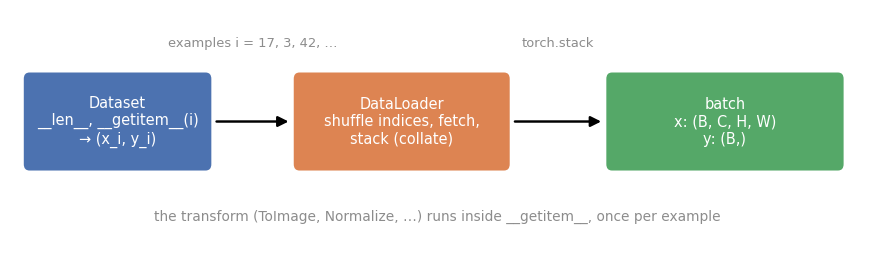

## 6.1 The `Dataset` protocol
A `Dataset` needs `__len__` (number of examples) and `__getitem__(i)` (example `i`, usually `(input, target)`). For data already in tensors, `TensorDataset` does it:

In [ ]:
from torch.utils.data import Dataset, TensorDataset, DataLoader, Subset

X = torch.randn(10, 3)                     # 10 examples, 3 features
y = torch.arange(10)                       # one label per example
ds = TensorDataset(X, y)                   # pairs them up, row by row
print("len(ds) =", len(ds))
x5, y5 = ds[5]                             # one example: a (features, label) tuple
print("ds[5] ->", x5, y5)

### A custom `Dataset`: predictive maintenance
Each example is a machine with four sensor readings (temperature °C, vibration mm/s, pressure bar, running hours); the label says whether it failed within a month. The readings have very different scales, so the dataset standardizes them, **with statistics it is given**:

In [ ]:
def make_sensor_data(n, seed=0):
    # Synthetic data: failure risk grows with temperature and vibration.
    g = torch.Generator().manual_seed(seed)
    temp = 60 + 15 * torch.randn(n, generator=g)
    vib = 3 + 1.5 * torch.randn(n, generator=g).abs()
    pres = 8 + 0.5 * torch.randn(n, generator=g)
    hours = 5000 * torch.rand(n, generator=g)
    X = torch.stack([temp, vib, pres, hours], dim=1)
    risk = 0.08 * (temp - 60) + 1.2 * (vib - 4) + 0.0002 * (hours - 2500)
    y = (risk + 0.5 * torch.randn(n, generator=g) > 0.5).long()
    return X, y

class SensorDataset(Dataset):
    def __init__(self, X, y, mean, std):
        self.X = (X - mean) / std          # standardize ONCE, with statistics we are given
        self.y = y

    def __len__(self):
        return len(self.y)

    def __getitem__(self, i):
        return self.X[i], self.y[i]

X_all, y_all = make_sensor_data(1000)
print("raw feature means:", X_all.mean(dim=0).round(decimals=1))    # wildly different scales
print("fraction of failures:", y_all.float().mean().item())

## 6.2 Splitting the data without leakage
| Split | Used for | Rule |
| --- | --- | --- |
| Training | computing gradients | |
| Validation | choosing hyper-parameters, epochs, the best checkpoint | never train on it |
| Test | one final, unbiased estimate | use it **once**, at the end |

**Data leakage** = information from validation/test data influencing training, which makes results look better than they are. A common form: computing standardization statistics on the whole dataset before splitting.

**Rule: fit every preprocessing step on the training split only, then apply the same frozen statistics everywhere.**

In [ ]:
# 1. Split the INDICES reproducibly: a seeded generator gives the same split on every run.
g = torch.Generator().manual_seed(0)
perm = torch.randperm(len(y_all), generator=g)
train_idx, val_idx = perm[:800], perm[800:]

# 2. Fit preprocessing on the TRAINING split only.
mean = X_all[train_idx].mean(dim=0)
std = X_all[train_idx].std(dim=0)

# 3. Apply the same statistics to every split.
train_ds = SensorDataset(X_all[train_idx], y_all[train_idx], mean, std)
val_ds = SensorDataset(X_all[val_idx], y_all[val_idx], mean, std)
print(len(train_ds), "training and", len(val_ds), "validation examples")
print("standardized training means:", train_ds.X.mean(dim=0).round(decimals=3))

`torch.utils.data.random_split(ds, [0.8, 0.2], generator=g)` is a shortcut; splitting indices yourself makes training-only statistics easy.

## 6.3 The `DataLoader`

In [ ]:
train_loader = DataLoader(train_ds, batch_size=64, shuffle=True)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False)

xb, yb = next(iter(train_loader))            # fetch one batch
print("one batch:", xb.shape, yb.shape, yb.dtype)
print("batches per epoch:", len(train_loader), "= ceil(800 / 64)")
sizes = [len(yb) for _, yb in train_loader]
print("batch sizes in one epoch:", sizes)     # the last batch is smaller: 800 = 12 * 64 + 32

| Argument | Meaning | Typical choice |
| --- | --- | --- |
| `batch_size` | examples per batch | 32–512 for training; larger for evaluation |
| `shuffle` | reshuffle at every epoch | `True` for training only |
| `drop_last` | drop the final smaller batch | `True` if tiny batches cause trouble (BatchNorm) |
| `num_workers` | background processes preparing batches | 2–8 if per-example work is slow; 0 = main process |
| `pin_memory` | page-locked memory for faster GPU copies | `True` with CUDA |

🤔 **Predict:** with `shuffle=True`, does the first batch start with the same labels in two epochs?

In [ ]:
for epoch in range(2):
    _, yb = next(iter(train_loader))
    print(f"epoch {epoch}: first 10 labels of the first batch: {yb[:10].tolist()}")

## 6.4 Image data with `torchvision`
**Fashion-MNIST**: 70,000 grayscale 28×28 images of clothing in 10 classes (60,000 train, 10,000 test). Harder than digit MNIST, so model differences are visible. A raw example is a PIL image:

In [ ]:
from torchvision import datasets
from torchvision.transforms import v2 as T       # the current transforms API

raw_train = datasets.FashionMNIST(DATA_DIR, train=True, download=True)   # no transform yet
CLASSES = raw_train.classes
img, label = raw_train[0]
print("type:", type(img).__name__, "| size:", img.size, "| mode:", img.mode)   # a PIL image
print("label:", label, "->", CLASSES[label])
print("all images as one uint8 tensor:", raw_train.data.shape, raw_train.data.dtype)

A **transform** runs inside `__getitem__` on every example; `T.Compose` chains several:
```python
T.Compose([T.ToImage(),                            # PIL -> uint8 tensor (C, H, W)
           T.ToDtype(torch.float32, scale=True),   # -> float32 in [0, 1]
           T.Normalize(mean=[m], std=[s])])        # -> (x - m) / s per channel
```
Older code uses `transforms.ToTensor()` for the first two steps; it gives the same values, but in the current `transforms.v2` API it is deprecated in favor of the two lines above.

Following §6.2, we split first (5,000 validation images) and compute the statistics on the training split only:

In [ ]:
g = torch.Generator().manual_seed(0)
perm = torch.randperm(len(raw_train), generator=g)
fm_val_idx, fm_train_idx = perm[:5000], perm[5000:]           # 5,000 validation, 55,000 training

train_pixels = raw_train.data[fm_train_idx].float() / 255     # (55000, 28, 28), training split only
FM_MEAN, FM_STD = train_pixels.mean().item(), train_pixels.std().item()
print(f"training-split pixel mean = {FM_MEAN:.4f}, std = {FM_STD:.4f}")

fm_transform = T.Compose([
    T.ToImage(),
    T.ToDtype(torch.float32, scale=True),
    T.Normalize(mean=[FM_MEAN], std=[FM_STD]),
])
x, label = datasets.FashionMNIST(DATA_DIR, train=True, transform=fm_transform)[0]
print("after the transform:", x.shape, x.dtype, f"| mean {x.mean():.2f}, std {x.std():.2f}")

**Always look at your data.** Wrong labels or broken normalization are visible at a glance:

In [ ]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, i in zip(axes.flat, range(16)):
    img, label = raw_train[i]
    ax.imshow(img, cmap="gray"); ax.set_title(CLASSES[label], fontsize=8); ax.axis("off")
plt.suptitle("Fashion-MNIST training examples"); plt.tight_layout(); plt.show()

## 🧪 Exercises
**Exercise 6.1: statistics over a loader.** `★★☆ · 15 min`
Write `channel_stats(loader)` returning per-channel mean and standard deviation `(C,)` over all pixels of all `(B, C, H, W)` batches. Accumulate sums; do not concatenate batches.

In [ ]:
# ✍️ Your attempt here.
# Hint: accumulate Σx and Σx² per channel with x.sum(dim=(0, 2, 3)) plus the pixel count; var = E[x²] − E[x]².

In [ ]:
# 🔎 Self-check for Exercise 6.1 (tests YOUR function)
def _test(fn):
    data = torch.rand(100, 3, 8, 8) * torch.tensor([1.0, 2.0, 3.0]).view(1, 3, 1, 1)
    loader = DataLoader(TensorDataset(data, torch.zeros(100)), batch_size=32)
    m, s = fn(loader)
    assert m.shape == (3,) and s.shape == (3,), "return two tensors of shape (C,)"
    ref = data.transpose(0, 1).reshape(3, -1)
    assert torch.allclose(m, ref.mean(dim=1), atol=1e-4), "means are wrong"
    assert torch.allclose(s, ref.std(dim=1, correction=0), atol=1e-3), "standard deviations are wrong"
self_check("channel_stats", _test)

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    def channel_stats(loader):
        s1, s2, count = 0.0, 0.0, 0
        for x, _ in loader:
            x = x.double()                                   # double precision: sums of many squares
            s1 = s1 + x.sum(dim=(0, 2, 3))
            s2 = s2 + (x ** 2).sum(dim=(0, 2, 3))
            count += x.shape[0] * x.shape[2] * x.shape[3]    # pixels per channel
        mean = s1 / count
        std = (s2 / count - mean ** 2).sqrt()
        return mean.float(), std.float()

    to_tensor = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True)])
    fm_plain = Subset(datasets.FashionMNIST(DATA_DIR, train=True, transform=to_tensor), fm_train_idx[:5000].tolist())
    print(channel_stats(DataLoader(fm_plain, batch_size=500)), "| full training split:", round(FM_MEAN, 4), round(FM_STD, 4))
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 6.2: train on the sensor data.** `★★☆ · 20 min`
Using `train_loader` and `val_loader` from §6.3, train an MLP `4 → 16 → 2` (ReLU) with `CrossEntropyLoss` and `Adam(lr=1e-2)` for 30 epochs **with mini-batches**. Report validation accuracy after each epoch (inside `no_grad`). Compare with the **majority-class baseline** (always predict "no failure").

In [ ]:
# ✍️ Your attempt here.
# Hint: two nested loops: over epochs and over train_loader, with the five-step training step inside.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    set_seed(0)
    sensor_model = nn.Sequential(nn.Linear(4, 16), nn.ReLU(), nn.Linear(16, 2))
    opt = torch.optim.Adam(sensor_model.parameters(), lr=1e-2)
    for epoch in range(30):
        sensor_model.train()
        for xb, yb in train_loader:
            loss = F.cross_entropy(sensor_model(xb), yb)
            opt.zero_grad(); loss.backward(); opt.step()
        sensor_model.eval()
        with torch.no_grad():
            correct = sum((sensor_model(xb).argmax(dim=1) == yb).sum().item() for xb, yb in val_loader)
        if epoch % 10 == 9:
            print(f"epoch {epoch + 1}: validation accuracy {correct / len(val_ds):.3f}")
    majority = max(val_ds.y.float().mean().item(), 1 - val_ds.y.float().mean().item())
    print(f"majority-class baseline: {majority:.3f}")
    # Always compare with this baseline: on imbalanced data, a high accuracy can mean very little.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- `Dataset` = how to get example `i`; `DataLoader` = shuffling, batching, parallel loading.
- Split first (seeded); fit preprocessing on the training split only; touch the test set once.
- Look at your data before training on it.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** 1,000 examples, `batch_size=64`: how many batches per epoch, and the size of the last one?

<details>
<summary>Answer</summary>

16 batches; the last has 40 examples (15 batches with `drop_last=True`).

</details>

**2.** A teammate standardizes the whole dataset, then splits. Why is that a problem?

<details>
<summary>Answer</summary>

The statistics contain information from the test examples (leakage), so test results are optimistically biased. Small for mean/std on big data, large for more powerful preprocessing.

</details>

---
# Chapter 7. Project: an MLP on Fashion-MNIST, end to end

🎯 Write reusable training and evaluation functions; compare against baselines; select the best epoch on validation data; test once; analyze errors; save and use the model.

The order you would follow at work: **data → baselines → training machinery → train → select on validation → test once → analyze errors → save**.

*Fresh session?* Run the Chapter 0 setup cell, then the hidden restore-point cell below (it does nothing if Chapters 4 and 6 already ran).

In [ ]:
# @title 🔁 Restore point for Chapter 7 (needed only if you start a fresh session here) { display-mode: "form" }
if "device" not in globals():
    raise RuntimeError("Run the Chapter 0 setup cells first, then this cell.")
if "fm_transform" not in globals():
    from torch.utils.data import Dataset, TensorDataset, DataLoader, Subset
    from torchvision import datasets
    from torchvision.transforms import v2 as T

    def count_params(m):
        return sum(p.numel() for p in m.parameters() if p.requires_grad)

    raw_train = datasets.FashionMNIST(DATA_DIR, train=True, download=True)
    CLASSES = raw_train.classes
    perm = torch.randperm(len(raw_train), generator=torch.Generator().manual_seed(0))
    fm_val_idx, fm_train_idx = perm[:5000], perm[5000:]
    train_pixels = raw_train.data[fm_train_idx].float() / 255
    FM_MEAN, FM_STD = train_pixels.mean().item(), train_pixels.std().item()
    fm_transform = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize(mean=[FM_MEAN], std=[FM_STD])])
    print("Restored the tools defined in earlier chapters.")

## 7.1 Data loaders
Same split and transform as §6.4: 55,000 training, 5,000 validation, 10,000 test images.

In [ ]:
import copy, sys

NUM_WORKERS = 2 if sys.platform.startswith("linux") else 0   # see the note below
PIN = device.type == "cuda"

full_train = datasets.FashionMNIST(DATA_DIR, train=True, transform=fm_transform)
test_set = datasets.FashionMNIST(DATA_DIR, train=False, download=True, transform=fm_transform)
fm_train = maybe_subset(Subset(full_train, fm_train_idx.tolist()))     # same indices as §6.4
fm_val = maybe_subset(Subset(full_train, fm_val_idx.tolist()))
fm_test = maybe_subset(test_set)

train_loader = DataLoader(fm_train, batch_size=128, shuffle=True, num_workers=NUM_WORKERS, pin_memory=PIN)
val_loader = DataLoader(fm_val, batch_size=512, num_workers=NUM_WORKERS, pin_memory=PIN)
test_loader = DataLoader(fm_test, batch_size=512, num_workers=NUM_WORKERS, pin_memory=PIN)
print(f"train {len(fm_train):,} | val {len(fm_val):,} | test {len(fm_test):,} | batches per epoch {len(train_loader)}")

**`num_workers`.** Workers prepare the next batches on other CPU cores while the GPU trains. Colab has 2 cores, hence 2. Each worker must be able to rebuild the `Dataset`; classes defined *inside a notebook* only work with the `fork` start method (Linux default up to Python 3.13), so we use 0 workers elsewhere. Here all classes come from `torchvision`, so it is safe.

## 7.2 Training and evaluation functions
Read every line: they combine Chapters 2–6.

In [ ]:
def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()                                   # Dropout/BatchNorm in training mode
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)           # move each batch to the model's device
        logits = model(x)                           # 1. forward
        loss = loss_fn(logits, y)                   # 2. loss (the MEAN over this batch)
        optimizer.zero_grad()                       # 3. clear old gradients
        loss.backward()                             # 4. backward
        optimizer.step()                            # 5. update
        total_loss += loss.item() * len(y)          # undo the mean: the last batch may be smaller
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


@torch.no_grad()                                    # decorator: the whole function runs without autograd
def evaluate(model, loader, loss_fn):
    model.eval()                                    # Dropout off, BatchNorm uses running statistics
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n

- `loss.item() * len(y)`: the loss is a batch **mean**; this gives the exact epoch mean even if the last batch is smaller.
- The training accuracy is approximate (weights change during the epoch; Dropout is on). Validation numbers come from `evaluate`.
- `model.train()` / `model.eval()` live **inside** the functions, so you cannot forget them.

`fit` runs the epochs, records a history and keeps the weights of the epoch with the **best validation accuracy**:

In [ ]:
def fit(model, train_loader, val_loader, loss_fn, optimizer, epochs):
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_acc, best_state = -1.0, None
    for epoch in range(1, epochs + 1):
        t0 = time.perf_counter()
        tr_loss, tr_acc = train_one_epoch(model, train_loader, loss_fn, optimizer)
        va_loss, va_acc = evaluate(model, val_loader, loss_fn)
        for key, value in zip(history, (tr_loss, tr_acc, va_loss, va_acc)):
            history[key].append(value)
        if va_acc > best_acc:                       # model selection with the VALIDATION set
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())   # a real copy, not a reference
        print(f"epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
              f"val loss {va_loss:.4f} acc {va_acc:.4f} | {time.perf_counter() - t0:4.1f}s")
    model.load_state_dict(best_state)               # end with the best weights, not the last ones
    print(f"best validation accuracy: {best_acc:.4f}")
    return history

⚠️ `model.state_dict()` returns **references** to the live tensors. Without `copy.deepcopy`, `best_state` would keep changing and you would "restore" the last weights.

**Which validation number to select on?** Here we keep the epoch with the best validation **accuracy**, the metric we report. Notebook 2 keeps the best validation **loss** instead: it is smoother (accuracy moves in steps of 1/N) and it also notices when the model becomes over-confident. Both are reasonable, as long as the choice is made before you look at the test set.

## 7.3 Baselines first
A number like "85 %" means nothing alone. Measure chance level and the simplest reasonable model first.

In [ ]:
loss_fn = nn.CrossEntropyLoss()

untrained = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)).to(device)
print("untrained model (chance level):", evaluate(untrained, val_loader, loss_fn))
print(f"  expected loss at chance: ln(10) = {math.log(10):.3f}; expected accuracy about 0.10")

set_seed(0)
linear = nn.Sequential(nn.Flatten(), nn.Linear(784, 10)).to(device)   # softmax regression
print("\nTraining a linear model (softmax regression):")
hist_linear = fit(linear, train_loader, val_loader, loss_fn,
                  torch.optim.AdamW(linear.parameters(), lr=1e-3), epochs=n_epochs(5))

**Sanity check:** when the predicted probabilities are close to uniform, the loss is about $\ln C$ ($\ln 10 \approx 2.30$). A freshly initialized model is usually near that value but not exactly on it (about 2.5 in our run), with accuracy near chance. A loss several times larger is a reason to check the inputs, labels and loss setup (§7.9) before training. The linear model reaches about 84 % validation accuracy: the bar the MLP must clear.

## 7.4 Training the MLP
784 → 256 → 128 → 10, ReLU, Dropout 0.2. Optimizer `AdamW(lr=1e-3)`: Adam plus **weight decay** (default 0.01), which pulls weights slightly toward zero every step; Notebook 2 explains it. Each epoch prints its time. On Colab that time is often limited by decoding and transforming the images on the CPU rather than by the GPU; Notebook 2 (Appendix E) measures this.

In [ ]:
set_seed(0)
mlp = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 256), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
    nn.Linear(128, 10),
).to(device)
print(f"parameters: {count_params(mlp):,}")
optimizer = torch.optim.AdamW(mlp.parameters(), lr=1e-3)
hist = fit(mlp, train_loader, val_loader, loss_fn, optimizer, epochs=n_epochs(15))

In [ ]:
def plot_history(hist, title=""):
    epochs = range(1, len(hist["train_loss"]) + 1)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.5))
    a1.plot(epochs, hist["train_loss"], "o-", label="train"); a1.plot(epochs, hist["val_loss"], "o-", label="validation")
    a1.set_xlabel("epoch"); a1.set_ylabel("loss"); a1.legend(); a1.set_title("Loss")
    a2.plot(epochs, hist["train_acc"], "o-", label="train"); a2.plot(epochs, hist["val_acc"], "o-", label="validation")
    a2.set_xlabel("epoch"); a2.set_ylabel("accuracy"); a2.legend(); a2.set_title("Accuracy")
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_history(hist, "MLP on Fashion-MNIST")

**Reading the curves.** Training loss keeps falling; validation loss falls, then flattens or creeps up; validation accuracy levels off near 88–89 %. The growing gap is **overfitting**. That is why `fit` keeps the best epoch. The best validation score is slightly optimistic (the maximum of noisy values), one more reason for an untouched test set. Your numbers will differ a little; the pattern is what matters.

## 7.5 The honest evaluation: test once
Architecture, learning rate and epoch were chosen on validation data only. Now, and only now, the test set:

In [ ]:
test_loss, test_acc = evaluate(mlp, test_loader, loss_fn)
print(f"MLP test accuracy:    {test_acc:.4f}  (test loss {test_loss:.4f})")
linear_test_acc = evaluate(linear, test_loader, loss_fn)[1]
print(f"linear test accuracy: {linear_test_acc:.4f}")
record("linear model, test accuracy", linear_test_acc)
record("MLP, test accuracy", test_acc)

## 7.6 Which mistakes? The confusion matrix
`C[i, j]` counts test images of true class `i` predicted as `j`; the diagonal is correct. The code turns each pair into one index `10·true + pred` and counts with `torch.bincount`.

In [ ]:
@torch.no_grad()
def predict_all(model, loader):
    model.eval()
    preds, targets = [], []
    for x, y in loader:
        preds.append(model(x.to(device)).argmax(dim=1).cpu())
        targets.append(y)
    return torch.cat(preds), torch.cat(targets)

pred, true = predict_all(mlp, test_loader)
cm = torch.bincount(true * 10 + pred, minlength=100).reshape(10, 10)

plt.figure(figsize=(7, 6))
plt.imshow(cm, cmap="Blues")
for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j].item(), ha="center", va="center", fontsize=7,
                 color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.xticks(range(10), CLASSES, rotation=60, fontsize=8); plt.yticks(range(10), CLASSES, fontsize=8)
plt.xlabel("predicted"); plt.ylabel("true"); plt.title("Confusion matrix (test set)")
plt.tight_layout(); plt.show()

per_class = cm.diag() / cm.sum(dim=1)
for i in per_class.argsort():
    print(f"{CLASSES[i]:12s} accuracy {per_class[i]:.3f}")

Trousers, bags and footwear are easy; **Shirt** is hardest, confused with T-shirt, pullover and coat. More epochs of the same MLP will not fix this. A model that sees local shapes, a **convolutional network** (Notebook 2), does better. Some of the mistakes:

In [ ]:
wrong = (pred != true).nonzero().squeeze(1)[:12]
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for ax, i in zip(axes.flat, wrong.tolist()):
    img, _ = test_set.data[i], test_set.targets[i]
    ax.imshow(img, cmap="gray"); ax.axis("off")
    ax.set_title(f"true: {CLASSES[true[i]]}\npred: {CLASSES[pred[i]]}", fontsize=8)
plt.suptitle("Misclassified test images"); plt.tight_layout(); plt.show()

## 7.7 Predicting one new image
In deployment, a single input needs: (1) **the same transform** as in training, (2) a **batch dimension**, (3) `eval()` and `no_grad()`, (4) softmax only now, to report a probability.

In [ ]:
@torch.no_grad()
def predict_image(model, pil_image):
    model.eval()                                        # 3.
    x = fm_transform(pil_image)                         # 1. (1, 28, 28), same preprocessing as training
    x = x.unsqueeze(0).to(device)                       # 2. (1, 1, 28, 28)
    probs = torch.softmax(model(x), dim=1)[0]           # 4. (10,)
    top = probs.argmax().item()
    return CLASSES[top], probs[top].item()

raw_test = datasets.FashionMNIST(DATA_DIR, train=False)   # the raw PIL images
for i in range(5):
    img, label = raw_test[i]
    name, p = predict_image(mlp, img)
    print(f"true: {CLASSES[label]:12s} predicted: {name:12s} (probability {p:.2f})")

## 7.8 Saving the model
Save the weights **with** everything needed to rebuild and use them: architecture settings, class names, normalization statistics.

In [ ]:
def build_mlp(hidden=(256, 128), p_drop=0.2):
    layers, d = [nn.Flatten()], 784
    for h in hidden:
        layers += [nn.Linear(d, h), nn.ReLU(), nn.Dropout(p_drop)]
        d = h
    return nn.Sequential(*layers, nn.Linear(d, 10))

bundle = {
    "state_dict": mlp.state_dict(),
    "config": {"hidden": (256, 128), "p_drop": 0.2},
    "classes": CLASSES,
    "normalization": {"mean": FM_MEAN, "std": FM_STD},
    "test_accuracy": test_acc,
}
torch.save(bundle, DATA_DIR / "fashion_mlp.pt")

# Later, possibly in another program:
loaded = torch.load(DATA_DIR / "fashion_mlp.pt", map_location="cpu")
model2 = build_mlp(**loaded["config"])
model2.load_state_dict(loaded["state_dict"])
model2.to(device)
print("reloaded model, test accuracy:", evaluate(model2, test_loader, loss_fn)[1], "| stored:", loaded["test_accuracy"])

## 7.9 When training does not work: two first checks
1. **Initial-loss sanity check:** for $C$ classes with nearly uniform predicted probabilities, cross-entropy is near $\ln C$ (for 10 classes, ≈ 2.30). Randomly initialized models need not predict uniformly; a larger initial loss is a *reason to investigate*, not proof of a bug.
2. **Overfit a small batch:** as a diagnostic, use a sufficiently expressive model, disable dropout or other strong regularization, and train on 32–64 examples for enough steps. Failure suggests inspecting labels, loss, preprocessing, learning rate, model capacity, and gradient/update logic; it does **not** isolate the cause to the implementation.

In [ ]:
set_seed(0)
xb, yb = next(iter(train_loader))
xb, yb = xb[:64].to(device), yb[:64].to(device)
probe = build_mlp(p_drop=0.0).to(device)                # no dropout: we WANT to memorize
opt = torch.optim.AdamW(probe.parameters(), lr=1e-3)
for step in range(201):
    loss = loss_fn(probe(xb), yb)
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 50 == 0:
        print(f"step {step:3d}  loss {loss.item():.4f}")

| Symptom | Most likely causes |
| --- | --- |
| Initial loss far above $\ln C$ | First check predicted probabilities and data/labels; this alone does not establish a bug |
| Loss exactly flat | `step()` missing or before `backward()`; parameters not registered; lr = 0 |
| Loss becomes `nan` | learning rate too high; `log(0)` in a hand-written loss |
| Cannot overfit one batch | Verify model capacity, optimizer and learning rate, labels, regularization, and output/target shapes |
| Noisy results between identical evaluations | `model.eval()` forgotten |
| Good validation, poor in production | different preprocessing at prediction time |

## 🧪 Exercises
**Exercise 7.1: capacity and regularization.** `★★☆ · 30 min (mostly waiting)`
With `build_mlp` and `fit`, train for 10 epochs: (a) `hidden=(64,)`, no dropout; (b) `hidden=(512, 256)`, no dropout; (c) `hidden=(512, 256)`, `p_drop=0.3`. Tabulate best validation accuracy and the final gap between validation and training loss. Which overfits most? Which generalizes best? Compare on **validation**, never test.

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    results = {}
    for name, cfg in {"(a) small": dict(hidden=(64,), p_drop=0.0),
                      "(b) big": dict(hidden=(512, 256), p_drop=0.0),
                      "(c) big + dropout": dict(hidden=(512, 256), p_drop=0.3)}.items():
        set_seed(0)
        m = build_mlp(**cfg).to(device)
        print(f"--- {name}")
        h = fit(m, train_loader, val_loader, loss_fn, torch.optim.AdamW(m.parameters(), lr=1e-3), n_epochs(10))
        results[name] = (max(h["val_acc"]), h["val_loss"][-1] - h["train_loss"][-1])
    for name, (acc, gap) in results.items():
        print(f"{name:20s} best val acc {acc:.4f} | final val-train loss gap {gap:+.3f}")
    # Typically: (b) has the largest gap (overfitting: high variance); (a) has a small gap but lower
    # accuracy (limited capacity: higher bias); (c) narrows the gap of (b) a lot, while its best validation
    # accuracy lands within a few tenths of a percent of (b)'s, above or below depending on the seed.
    # Capacity and regularization are tuned together, and a single run cannot rank (b) and (c).
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 7.2: SGD, momentum and AdamW.** `★★☆ · 20 min`
Train `build_mlp()` for 10 epochs with (a) `SGD(lr=0.1)`, (b) `SGD(lr=0.01, momentum=0.9)`, (c) `AdamW(lr=1e-3)` and plot the three validation-accuracy curves.
Why is (b) a fair comparison with (a)? PyTorch's momentum keeps $v \leftarrow 0.9\,v + g$, a running **sum**; for a steady gradient $v \to g/(1 - 0.9) = 10g$, so lr 0.01 with momentum takes steps comparable to lr 0.1 without. Which converges fastest?

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    curves = {}
    for name, make_opt in {"SGD lr=0.1": lambda p: torch.optim.SGD(p, lr=0.1),
                           "SGD+momentum lr=0.01": lambda p: torch.optim.SGD(p, lr=0.01, momentum=0.9),
                           "AdamW lr=1e-3": lambda p: torch.optim.AdamW(p, lr=1e-3)}.items():
        set_seed(0)
        m = build_mlp().to(device)
        print(f"--- {name}")
        curves[name] = fit(m, train_loader, val_loader, loss_fn, make_opt(m.parameters()), n_epochs(10))["val_acc"]
    plt.figure(figsize=(6, 3.5))
    for name, c in curves.items():
        plt.plot(range(1, len(c) + 1), c, "o-", label=name)
    plt.xlabel("epoch"); plt.ylabel("validation accuracy"); plt.legend(); plt.show()
    # With the same effective step size, momentum mainly smooths the noisy mini-batch gradients, so (b) is
    # usually a little steadier than (a); AdamW usually gets there in the fewest epochs. Rankings depend on
    # the learning rates, so optimizers are compared at their own well-chosen learning rates.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

**Exercise 7.3: a new dataset in one line.** `★☆☆ · 10 min`
Replace `datasets.FashionMNIST` with `datasets.MNIST`, **recompute** the normalization statistics on MNIST's own training split (§6.2), and train `build_mlp()` for 5 epochs. Test accuracy? Why higher than on Fashion-MNIST?

In [ ]:
# ✍️ Your attempt here.

In [ ]:
# @title ✅ Solution (double-click to reveal) { display-mode: "form" }
# Solutions only execute when RUN_SOLUTIONS = True (setup cell), so "Run all" stays fast.
if RUN_SOLUTIONS:
    mn_raw = datasets.MNIST(DATA_DIR, train=True, download=True)
    # MNIST also has 60,000 training images, so the same 55,000 / 5,000 index split can be reused.
    mn_pixels = mn_raw.data[fm_train_idx].float() / 255                     # MNIST's training split only
    mn_mean, mn_std = mn_pixels.mean().item(), mn_pixels.std().item()
    print(f"MNIST statistics: mean {mn_mean:.4f}, std {mn_std:.4f}  (Fashion-MNIST: {FM_MEAN:.4f}, {FM_STD:.4f})")
    mn_tf = T.Compose([T.ToImage(), T.ToDtype(torch.float32, scale=True), T.Normalize([mn_mean], [mn_std])])
    mn_train_full = datasets.MNIST(DATA_DIR, train=True, transform=mn_tf)
    mn_test = maybe_subset(datasets.MNIST(DATA_DIR, train=False, download=True, transform=mn_tf))
    mn_train = maybe_subset(Subset(mn_train_full, fm_train_idx.tolist()))
    mn_val = maybe_subset(Subset(mn_train_full, fm_val_idx.tolist()))
    set_seed(0)
    m = build_mlp().to(device)
    fit(m, DataLoader(mn_train, batch_size=128, shuffle=True, num_workers=NUM_WORKERS),
        DataLoader(mn_val, batch_size=512, num_workers=NUM_WORKERS),
        loss_fn, torch.optim.AdamW(m.parameters(), lr=1e-3), n_epochs(5))
    print("MNIST test accuracy:", evaluate(m, DataLoader(mn_test, batch_size=512), loss_fn)[1])
    # Typically about 98%: digits are separated by simple stroke patterns, while several Fashion-MNIST
    # classes (shirt, T-shirt, pullover, coat) differ only in subtle details. Nothing else in the
    # pipeline had to change, which is the point of separating data, model and training loop.
else:
    print("Solution not executed (RUN_SOLUTIONS = False).")

### 📌 Key takeaways
- Put `train()` / `eval()` / `no_grad()` inside your training and evaluation functions.
- Compare against baselines; check initial loss ≈ ln C; overfit one batch.
- Select on validation; test once; keep the best weights with `copy.deepcopy`.
- At prediction time: same preprocessing, a batch dimension, `eval()`, `no_grad()`.

### ✔️ Check yourself
Answer each question *before* expanding it.

**1.** After seeing the test accuracy you add dropout and the test accuracy improves. Is the new number unbiased?

<details>
<summary>Answer</summary>

No. The test set influenced a decision, so it has become a validation set.

</details>

**2.** The model works in the notebook but not on images from a web app. First check?

<details>
<summary>Answer</summary>

Identical preprocessing: scaling to [0, 1], the same normalization statistics, size and channel layout, a batch dimension, `eval()` mode.

</details>

---
# Summary: the template
```python
# ---- data ----
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds, batch_size=512)

# ---- model, loss, optimizer ----
model = MyModel().to(device)                     # outputs LOGITS
loss_fn = nn.CrossEntropyLoss()                  # int64 targets of shape (N,)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3)

# ---- training ----
for epoch in range(epochs):
    model.train()
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        loss = loss_fn(model(x), y)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    model.eval()
    with torch.no_grad():
        ...                                      # validation metrics; keep the best weights

# ---- once, at the end ----
test_metrics = evaluate(model, test_loader, loss_fn)
torch.save({"state_dict": model.state_dict(), "config": cfg}, "model.pt")
```

## Your results
Values quoted in the text are typical, not guaranteed. Your run is the ground truth:

In [ ]:
for name, value in RESULTS.items():
    print(f"{name:35s} {value:.4f}")

## Next: Notebook 2
Training craft for MLPs, and optional further reading on convolution: initialization and activations, optimizers and learning-rate schedules, regularization and early stopping, checkpoints and reproducibility, evaluation beyond accuracy, a small CNN, debugging, and preparing a model for use.

---
## Instructor notes (October 2026)
- **Versions.** The notebook runs on whatever recent PyTorch (2.6 or newer) students have; the setup cell prints the versions. It relies on `torch.load(weights_only=True)` being the default (PyTorch 2.6 and newer) and on `torchvision.transforms.v2`.
- **Demonstration values are not guarantees.** Random seeds, PyTorch/CUDA/torchvision versions, hardware, and kernel state can affect displayed metrics and runtimes.
- **Clean-run check:** restart the kernel and run everything with `FAST_DEV_RUN = True` (about a minute), then once with the normal settings so the datasets are cached before class. Set `RUN_SOLUTIONS = True` to execute the exercise solutions as well.
- **Losses:** supply raw logits to `CrossEntropyLoss` / `BCEWithLogitsLoss`; do not add softmax/sigmoid before these losses.
- **Evaluation:** do not tune hyperparameters or thresholds on the test set; use a validation split.
- **Colab:** GPU availability varies. Confirm that the device printed by the setup cell matches the runtime you selected.

**Changes in this revision (v5):** §7.3's initial-loss check now agrees with §7.9 (near $\ln C$, not exactly; a much larger value is a reason to investigate); §7.4 no longer promises a per-epoch time. Earlier (v4): American spelling throughout; Chapter 0 section numbering; the setup cell prints the Python version; precise wording for `inference_mode`; §7.2 explains why the best epoch is selected on validation accuracy here and on validation loss in Notebook 2; the Exercise 7.1 solution no longer promises that dropout beats the unregularized model.

References: [PyTorch tutorials](https://docs.pytorch.org/tutorials/), [Autograd mechanics](https://docs.pytorch.org/docs/stable/notes/autograd.html), [Adam](https://docs.pytorch.org/docs/stable/generated/torch.optim.Adam.html), [AdamW](https://docs.pytorch.org/docs/stable/generated/torch.optim.AdamW.html), [LR schedulers](https://docs.pytorch.org/docs/stable/optim.html), [Serialization](https://docs.pytorch.org/docs/stable/notes/serialization.html).